# VNET CONTRASTIVE SELF-SUPERVISED PRETRAINING (TF-C style) with leave-one-individual-out CV

Companion notebook to `B_Training_the_Vnet_Green_Turtles_pytorch_hyperparam_sweep.ipynb` and `B_bis_Training_Vnet_GT_LOOCV.ipynb`. Same data access and same VNet architecture, but the encoders are first pretrained **without labels** with time-frequency consistency (TF-C) contrastive learning, then fully fine-tuned on the labelled recordings. The whole pipeline is wrapped in a **leave-one-individual-out cross-validation (LOOCV)** loop that reuses the recording list, the individual grouping (`INDIVIDUAL_OVERRIDES`) and the per-fold train/validation split of the supervised LOOCV notebook, so fold *k* here is the same held-out individual, with the same validation individuals, as fold *k* there.

Background:
- Zhang et al., *Self-Supervised Contrastive Pre-Training for Time Series via Time-Frequency Consistency (TF-C)*
- Tang et al., *Exploring Contrastive Learning in Human Activity Recognition for Healthcare*
- Haresamudram et al., *Assessing the State of Self-Supervised Human Activity Recognition Using Wearables*
- *Contrastive Self-Supervised Learning for Sensor-based Human Activity Recognition*

**Pipeline (repeated inside every fold)**
0. Split: one individual is the TEST set. Of the remaining individuals, `N_VAL_INDIVIDUALS_PER_FOLD` (drawn with `RandomState(fold_idx)`, as in the supervised LOOCV) are VALIDATION and the rest are TRAIN.
1. Pool the fold's labelled **TRAIN** recordings and all CC-09 (unlabelled) recordings. VAL and the held-out TEST individual are excluded from the pool; labels are not read at this stage. The frequency-standardisation statistics are re-fitted on this pool, so nothing about the held-out individual leaks into pretraining.
2. Sample random 40 s windows (800 samples) from the pool.
3. Build four views of each window: the original time window, the time window plus one random augmentation (noise, scaling or a small time shift), the original per-1.25 s-segment magnitude spectrum (log1p, standardised), and the same spectrum after one random frequency augmentation (TF-C: remove or add E = 1 frequency component, alpha = 0.5). The frequency augmentation perturbs the magnitude spectrum itself, before the log and standardisation.
4. Encode the time pair with a shared `encoder_t` and the frequency pair with a shared `encoder_f` (both `VNet4Levels`, half width, spatial dropout 0.1 during pretraining and 0.5 during fine-tuning). The final decoder feature map of each encoder is mean-pooled **inside 1.25 s segments only**, giving 32 segment features `h` per window and view. A two-layer projector (`R_T`, `R_F`) maps `h` to the embedding `z`. Each of the four views is first circularly rolled by its own random number of whole segments (`TFC_ROLL`) and the segment features are rolled back after encoding: the segment pairing is unchanged, but no two views of a pair share the same absolute position in the window (in the diagnostics the embeddings otherwise encoded the segment position, position-probe accuracy about 0.95 against about 0.1 with rolling).
5. Loss (TF-C, Eq. 4): `L = λ(L_T + L_F) + (1-λ) L_C`. `L_T` and `L_F` contrast the original and augmented view within each domain (on `h`). `L_C` is the time-frequency consistency term (on `z`): `sum_pair (S_TF - S_pair + delta)` as in Eq. 3 but with each term hinged at 0, `sum_pair max(0, S_TF - S_pair + delta)` (`TFC_HINGE`): the un-hinged form is unbounded below and was driven to about -15 in the diagnostics. All distances `d` are NT-Xent with the other segments in the batch as negatives; paper settings tau = 0.2, delta = 1, lambda = 0.5. Pretraining runs until the smoothed loss plateaus (`SSL_PATIENCE`), up to `SSL_EPOCHS`.
6. Keep the pretrained encoders **and projectors**, attach a fresh 2-layer MLP head (hidden 64) to the concatenated `[z_T ; z_F]` and fine-tune the **whole network end to end** on the fold's TRAIN individuals with the paper's optimiser settings (Adam, lr 3e-4, weight decay 5e-4, batch 64). The paper's appendix also optimises the TF-C loss jointly with the classification loss; that auxiliary term is switched off here (`FT_TFC_AUX_WEIGHT = 0`), as in the diagnostics' end-to-end check. Class-balanced windows, weighted cross-entropy, early stopping on the fold's VAL individuals, best checkpoint restored.
7. Evaluate on the held-out individual. Validation and test sets are built by the same function (non-overlapping 40 s windows, one majority label per 1.25 s segment) and scored per 1.25 s segment.
8. Control (same fold, same budget, same early stopping): the identical classifier trained from random initialisation, so the effect of pretraining is measured per fold.

The headline score is the macro-F1 over the classes present in the held-out individual, excluding `Other`, averaged over folds (the same definition as in the supervised LOOCV notebook). Predictions are per 1.25 s segment rather than per timestep, so the scores are not directly comparable with the dense per-timestep baseline.

## 0. Imports

In [4]:
import os
import sys
import time
import copy
import json
import datetime
from pathlib import Path
from pprint import pprint

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader

import sklearn.metrics
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.utils.multiclass import unique_labels
import random
import re
import gc
from collections import defaultdict

np.set_printoptions(precision=2, suppress=True, linewidth=50000)

# same working directory convention as the supervised notebook -- change as needed
# os.chdir(r"C:\Users\Bea Loubser\OneDrive\Desktop\Thesis\Vnet_seaturtles_semisupervised\notebooks")
print(os.getcwd())

torch.__version__

/home/24823716/Downloads


'2.14.1+cu130'

In [5]:
""" a dictionary to store all the information """
memo = pd.Series(dtype=object)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [6]:
def set_seed(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        torch.xpu.manual_seed_all(seed)

## Parameters

Same class/descriptor/window setup as the supervised baseline, plus the 1.25 s segment size used for pooling and classification, the SSL and fine-tuning hyperparameters, and the LOOCV run controls.

**Epoch budgets** (no compute limit, so these are generous ceilings, not fixed schedules): pretraining is capped at 100 epochs (the length used in the diagnostics' end-to-end check; the frozen-probe scores at 10, 20, 40 and 100 epochs did not improve with longer pretraining) and fine-tuning is raised from 50 to 200 epochs. Both now stop themselves — pretraining when the (5-epoch smoothed) TF-C loss has not improved for `SSL_PATIENCE` epochs, fine-tuning when the validation loss has not improved for `FINETUNE_PATIENCE` epochs — and the best checkpoint is restored, so a larger ceiling costs nothing once a stage has converged.

**Pretraining recipe** (variant `combo_roll` of `tfc_diagnostics.py`, diagnosed on folds 1 and 2): `TFC_ROLL`, `TFC_HINGE` and `TFC_PRETRAIN_DROPOUT = 0.1`. `FT_TFC_AUX_WEIGHT = 0` matches the diagnostics' end-to-end check, which fine-tuned with the auxiliary TF-C loss off.

In [ ]:
CASE = memo["CASE"] = "SSL_contrastive_pretrain_B_roll_hinge_seg1.25_LOOCV"  # give a different name if you change parameters (finished folds of a run folder are reloaded, not retrained)

class classCLASS:
    def __init__(self, id, name, behaviors, score_weight, sampling_weight=1, loss_weight=1):
        self.id = id
        self.name = name
        self.behaviors = behaviors
        self.score_weight = score_weight
        self.sampling_weight = sampling_weight
        self.loss_weight = loss_weight

Other = classCLASS(0, "Other", None, 0, 1, 0.1)
Breathing = classCLASS(1, "Breathing", [1, 2, 40], 1)
Feeding = classCLASS(2, "Feeding", [3, 4, 5, 6, 7, 11, 12, 13, 18, 19, 20, 21], 10, 2, 2)
Gliding = classCLASS(3, "Gliding", [16, 17], 1, 3)
Resting = classCLASS(4, "Resting", [29, 30, 31, 32], 1, 0.5)
Scratching = classCLASS(5, "Scratching", [34, 35, 36], 2, 2, 2)
Swimming = classCLASS(6, "Swimming", [42, 45, 48, 43, 46, 49, 27, 44, 47, 50, 56, 52, 54, 55], 1, 0.5)

CLASSES = [Other, Breathing, Feeding, Gliding, Resting, Scratching, Swimming]

DESCRIPTORS_SELEC_UNLAB = [0, 1, 2, 3, 4, 5, 9]
DESCRIPTORS_SELEC = [1, 2, 3, 4, 5, 6, 25]    # channels in the out_A_09062025 files
DESCRIPTORS_SELEC2 = [0, 1, 2, 3, 4, 5, 24]   # the same 7 channels in the out_B files (column layout shifted by one)
WINDOW_DURA = 40
RESAMPLING_STEP_S = 0.0500
DIR_IN = "Data/out_A_09062025"
DIR_IN_B = "Data/out_B"                       # CC-09-72_04-11-2022 (labelled) lives here, see load_mat
DIR_IN_UNLAB = "Data/TV_processed_unlabelled"

WINDOW_SIZE = int(WINDOW_DURA / RESAMPLING_STEP_S) 
# Pooling / classification unit: nothing is ever pooled over more than one segment
SEG_DURA = 1.25                                       # seconds
SEG_LEN = round(SEG_DURA / RESAMPLING_STEP_S)         # 25 samples
N_SEG = WINDOW_SIZE // SEG_LEN                        # 32 segments per 40 s window
assert abs(SEG_DURA / RESAMPLING_STEP_S - SEG_LEN) < 1e-6, "SEG_DURA must be a whole number of samples"
assert WINDOW_SIZE % SEG_LEN == 0 and N_SEG % 8 == 0  # N_SEG % 8: keeps the 3 stride-2 downsamples symmetric for the frequency encoder

COL_BEH = 27   # behaviour column in the out_A files (COL_BEH - 1 in the out_B files)

LR_initial = 0.0001
BATCH_SIZE = 32
MODEL_DEPTH = 32
MODEL_HEAD = "softmax"
DROPOUT = 0.5

seed = SEED = 42
set_seed(seed)   # python, numpy, torch (all window/augmentation sampling uses np.random)

TFC_LAMBDA = 0.5   # L = lam*(L_T + L_F) + (1-lam)*L_C   (paper: 0.5)
TFC_DELTA = 1.0    # margin in L_C                       (paper: 1.0)
FREQ_AUG_E = 1       # frequency components perturbed per spectrum   (paper: E = 1)
FREQ_AUG_ALPHA = 0.5 # added component is raised to alpha * max amplitude (paper: 0.5)

# --- Pretraining recipe from the diagnostics (tfc_diagnostics.py, variant "combo_roll", folds 1 and 2) ----------
TFC_ROLL = True              # every view is circularly rolled by its own random number of whole segments before encoding (removes the segment-position shortcut)
TFC_HINGE = True             # hinge the L_C terms: max(0, S_TF - S_pair + delta). The un-hinged L_C is unbounded below (it drifted to about -15)
TFC_PRETRAIN_DROPOUT = 0.1   # encoder spatial dropout during PRETRAINING only; fine-tuning keeps DROPOUT = 0.5 (as in the diagnostics)

# --- Contrastive pretraining hyperparameters -------------------------------
PROJ_HIDDEN_DIM = 256      # projection-head hidden width
PROJ_OUT_DIM = 128         # embedding dim the NT-Xent loss operates on
NTXENT_TEMPERATURE = 0.2   # softmax temperature tau        (paper: 0.2)
SSL_BATCH_SIZE = 64        # windows per batch -> SSL_BATCH_SIZE * N_SEG segment pairs per batch
SSL_WINDOWS_PER_EPOCH = 4000   # one "epoch" = 4000 random windows (~63 optimiser steps), unchanged
SSL_EPOCHS = 300           # CEILING, the length used in the diagnostics' end-to-end check (was 600). Pretraining ends earlier if the smoothed loss plateaus (SSL_PATIENCE)
SSL_PATIENCE = 30          # stop after this many epochs without the smoothed TF-C loss improving by SSL_MIN_DELTA
SSL_MIN_DELTA = 1e-3
SSL_SMOOTH_WINDOW = 5      # epochs averaged before comparing losses (epoch losses are noisy: every epoch draws new random windows)
SSL_LR = 0.0003            # paper: Adam, lr 3e-4
SSL_WEIGHT_DECAY = 0.0005  # paper: 2-norm penalty 5e-4

# --- Fine-tuning hyperparameters (full end-to-end fine-tune) ---------------
FINETUNE_EPOCHS = 200          # Early stopping on the fold's validation loss ends it earlier
FINETUNE_PATIENCE = 25        
FINETUNE_LR = 0.0003           # paper: fine-tuning uses the same optimiser settings as pre-training
FINETUNE_WEIGHT_DECAY = 0.0005
FINETUNE_BATCH_SIZE = 64       # paper: 64
FT_TFC_AUX_WEIGHT = 0.0        # off, as in the diagnostics' end-to-end check (paper App. E optimises the classification loss jointly with L_TF-C: set 1.0 for that)
FT_HEAD_HIDDEN = 64            # paper: 2-layer classifier, hidden 64
# --- LOOCV / run controls --------------------------------------------------
N_VAL_INDIVIDUALS_PER_FOLD = 2   # remaining individuals held out for validation in every fold (as in the supervised LOOCV)
RUN_SCRATCH_CONTROL = True       # per fold, also train the identical classifier from random init (measures the effect of pretraining)
MAX_FOLDS = None                 # e.g. 1 to time a single fold before launching the full run; None = all folds
RESUME_DIR = None                # set to an existing run folder to skip folds that already finished there
LOG_EVERY = 10                   # print every n-th epoch (14 folds x several hundred epochs is a lot of output otherwise)

## Recordings, grouped by individual

Identical to the supervised LOOCV notebook: recording names are `<camera>_<date>[_<part>]`, the `CC-0X-XX` part is the camera ID (not the animal), so each distinct camera + date is one individual, a same-day recording split into parts is merged back into one individual, and `CC-07-115_13-05-2019` / `CC-07-115_14-05-2019` are merged by `INDIVIDUAL_OVERRIDES`. The folds (and therefore the held-out individual, validation individuals and training individuals of every fold) are therefore the same as in the supervised LOOCV.

In [8]:
# All labelled recordings -- the same pool as the supervised LOOCV notebook (B_bis_Training_Vnet_GT_LOOCV)
NAMES_ALL = [
    'CC-07-48_18-02-2019',
    'CC-07-48_06-10-2018',
    'CC-07-48_04-10-2018',
    'CC-07-115_13-05-2019',
    'CC-07-115_14-05-2019',
    'CC-07-48_08-04-2019_1',
    'CC-07-48_08-04-2019_2',
    'CC-07-48_08-04-2019_3',
    'CC-07-48_22-05-2018',
    'CC-07-108_11-02-2019',
    'CC-07-59_20-05-2018',
    'CC-07-47_14-02-2018',
    'CC-07-48_10-10-2018',
    'CC-07-48_08-10-2018',
    'CC-07-48_26-05-2018',
    'CC-07-107_11-02-2019',
    'CC-09-72_04-11-2022',
]
memo["NAMES_ALL"] = NAMES_ALL

INDIVIDUAL_OVERRIDES = {
    'CC-07-115_13-05-2019': 'CC-07-115_13-05-2019+14-05-2019',
    'CC-07-115_14-05-2019': 'CC-07-115_13-05-2019+14-05-2019',
}


def individual_id_of(name):
    """'CC-07-48_08-04-2019_1' -> 'CC-07-48_08-04-2019' (same camera+date, just a split file -> same individual/session),
    unless overridden in INDIVIDUAL_OVERRIDES."""
    if name in INDIVIDUAL_OVERRIDES:
        return INDIVIDUAL_OVERRIDES[name]
    return re.sub(r'_\d+$', '', name)   # strip a trailing '_<part number>' suffix


INDIVIDUAL_TO_NAMES = defaultdict(list)
for name in NAMES_ALL:
    INDIVIDUAL_TO_NAMES[individual_id_of(name)].append(name)

INDIVIDUAL_IDS = sorted(INDIVIDUAL_TO_NAMES.keys())

print(f"{len(NAMES_ALL)} recordings, {len(INDIVIDUAL_IDS)} distinct individuals:")
for iid in INDIVIDUAL_IDS:
    print(f"  {iid}: {len(INDIVIDUAL_TO_NAMES[iid])} recording(s) -> {INDIVIDUAL_TO_NAMES[iid]}")

# Unlabelled (CC-09) -- used ONLY for pretraining, never for finetune/eval
NAMES_ALL_UNLAB = [
    '20211130-203207-CC-09-29_TV_112021',
    '20211114-120603-CC-09-28_TV_102021',
    '20211122-104139-CC-09-28_TV_102021',
    '20220414-002025-CC-09-80',
    '20211108-055826-CC-09-28_TV_102021',
    '20211024-141045-CC-09-29_TV_102021',
    '20211101-081704-CC-09-28_TV_102021',
    '20211102-115134-CC-09-29_TV_102021',
    '20211113-213025-CC-09-29_TV_112021',
    '20211107-072758-CC-09-29_TV_102021',
    '20220508-195728-CC-09-80',
    '20220114-125839-CC-09-29_TV_012022',
    '20220421-211441-CC-09-80',
    '20211121-203649-CC-09-29_TV_112021',
]
memo["NAMES_ALL_UNLAB"] = NAMES_ALL_UNLAB

17 recordings, 14 distinct individuals:
  CC-07-107_11-02-2019: 1 recording(s) -> ['CC-07-107_11-02-2019']
  CC-07-108_11-02-2019: 1 recording(s) -> ['CC-07-108_11-02-2019']
  CC-07-115_13-05-2019+14-05-2019: 2 recording(s) -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019']
  CC-07-47_14-02-2018: 1 recording(s) -> ['CC-07-47_14-02-2018']
  CC-07-48_04-10-2018: 1 recording(s) -> ['CC-07-48_04-10-2018']
  CC-07-48_06-10-2018: 1 recording(s) -> ['CC-07-48_06-10-2018']
  CC-07-48_08-04-2019: 3 recording(s) -> ['CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3']
  CC-07-48_08-10-2018: 1 recording(s) -> ['CC-07-48_08-10-2018']
  CC-07-48_10-10-2018: 1 recording(s) -> ['CC-07-48_10-10-2018']
  CC-07-48_18-02-2019: 1 recording(s) -> ['CC-07-48_18-02-2019']
  CC-07-48_22-05-2018: 1 recording(s) -> ['CC-07-48_22-05-2018']
  CC-07-48_26-05-2018: 1 recording(s) -> ['CC-07-48_26-05-2018']
  CC-07-59_20-05-2018: 1 recording(s) -> ['CC-07-59_20-05-2018']
  CC-09-72_04-11-2022:

In [9]:
memo["MODEL_HEAD"] = MODEL_HEAD
memo["MODEL_DEPTH"] = MODEL_DEPTH
memo["BATCH_SIZE"] = BATCH_SIZE
memo["LR_initial"] = LR_initial
memo["WINDOW_DURA"] = WINDOW_DURA
memo["DIR_IN"] = DIR_IN
memo["DIR_IN_B"] = DIR_IN_B
memo["DIR_IN_UNLAB"] = DIR_IN_UNLAB
memo["RESAMPLING_STEP_S"] = RESAMPLING_STEP_S
for CLASS in CLASSES:
    memo["CLASSES_" + CLASS.name] = CLASS.__dict__
memo["DROPOUT"] = DROPOUT
memo["DESCRIPTORS_SELEC"] = DESCRIPTORS_SELEC
memo["DESCRIPTORS_SELEC2"] = DESCRIPTORS_SELEC2
memo["SSL_EPOCHS"] = SSL_EPOCHS
memo["SSL_PATIENCE"] = SSL_PATIENCE
memo["SSL_MIN_DELTA"] = SSL_MIN_DELTA
memo["SSL_SMOOTH_WINDOW"] = SSL_SMOOTH_WINDOW
memo["SSL_BATCH_SIZE"] = SSL_BATCH_SIZE
memo["SSL_WINDOWS_PER_EPOCH"] = SSL_WINDOWS_PER_EPOCH
memo["NTXENT_TEMPERATURE"] = NTXENT_TEMPERATURE
memo["TFC_LAMBDA"] = TFC_LAMBDA
memo["TFC_DELTA"] = TFC_DELTA
memo["SEG_DURA"] = SEG_DURA
memo["SEG_LEN"] = SEG_LEN
memo["N_SEG"] = N_SEG
memo["SSL_LR"] = SSL_LR
memo["SSL_WEIGHT_DECAY"] = SSL_WEIGHT_DECAY
memo["FREQ_AUG_E"] = FREQ_AUG_E
memo["FREQ_AUG_ALPHA"] = FREQ_AUG_ALPHA
memo["FINETUNE_EPOCHS"] = FINETUNE_EPOCHS
memo["FINETUNE_PATIENCE"] = FINETUNE_PATIENCE
memo["FINETUNE_LR"] = FINETUNE_LR
memo["FINETUNE_BATCH_SIZE"] = FINETUNE_BATCH_SIZE
memo["FT_TFC_AUX_WEIGHT"] = FT_TFC_AUX_WEIGHT
memo["N_VAL_INDIVIDUALS_PER_FOLD"] = N_VAL_INDIVIDUALS_PER_FOLD
memo["TFC_ROLL"] = TFC_ROLL
memo["TFC_HINGE"] = TFC_HINGE
memo["TFC_PRETRAIN_DROPOUT"] = TFC_PRETRAIN_DROPOUT

### Create folder to save results

One run folder; every fold writes its own sub-folder (`pretrain/`, `finetune/`, `scratch/`, loss curves, test predictions, `fold_result.json`). Set `RESUME_DIR` to an existing run folder to continue an interrupted run: folds with a saved `fold_result.json` are loaded instead of re-trained.

In [10]:
now = datetime.datetime.now()
today = now.strftime("%Y_%m_%d")

DIR_OUT = RESUME_DIR or f"Model_results/modelVNET_TFC_LOOCV={today}_{CASE}"
os.makedirs(DIR_OUT, exist_ok=True)
print("output dir ready:", DIR_OUT)

output dir ready: Model_results/modelVNET_TFC_LOOCV=2026_10_06_SSL_contrastive_pretrain_B_roll_hinge_seg1.25_LOOCV


## 1. Load the data (once, shared across all folds)

Same loaders as the supervised baseline. `load_mat` reads and per-file-normalizes the labelled recordings (labels included, `labels` dict populated); recordings that are not in `out_A_09062025` are looked up in `out_B` (which has its behaviour column and channels one position to the left), exactly as in the supervised LOOCV notebook. `load_mat_UNLAB` does the same for CC-09 but has no labels to read. For contrastive pretraining, `labels` is never touched.

In [11]:
def load_dico(path, key_int=False, print_me=False):
    with open(path) as f:
        dico_str = json.loads(json.load(f))
    conv_key = (lambda k: int(k)) if key_int else (lambda k: k)
    dico = {conv_key(k): v for k, v in dico_str.items()}
    if print_me:
        print(dico)
    return dico


def load_mat(names):
    """Labelled recordings. out_A_09062025 first (behaviour column COL_BEH, channels DESCRIPTORS_SELEC);
    otherwise out_B (behaviour column COL_BEH - 1, channels DESCRIPTORS_SELEC2) -- same rule as the supervised LOOCV notebook."""
    matrices, labels = {}, {}
    for name in names:
        path_a = DIR_IN + "/" + name + ".npy"
        path_b = DIR_IN_B + "/" + name + ".npy"
        if os.path.exists(path_a):
            full_name, col_beh, cols = path_a, COL_BEH, DESCRIPTORS_SELEC
        elif os.path.exists(path_b):
            full_name, col_beh, cols = path_b, COL_BEH - 1, DESCRIPTORS_SELEC2
        else:
            raise FileNotFoundError(f"The file: {name}.npy cannot be found in {DIR_IN} or {DIR_IN_B}")
        full_mat = np.load(full_name)
        pre_label = full_mat[:, col_beh]

        label = np.zeros_like(pre_label)
        for CLASS in CLASSES:
            if CLASS != Other:
                for beh in CLASS.behaviors:
                    label[pre_label == beh] = CLASS.id

        mat = full_mat[:, cols]
        print("loading:", name, "from", full_name.split("/")[-2], "shape:", mat.shape,
              "duration (hrs):", round(len(mat) * RESAMPLING_STEP_S / 3600, 2))

        matrices[name] = mat
        labels[name] = label
    return matrices, labels


def load_mat_UNLAB(names):
    matrices = {}
    for name in names:
        full_name = DIR_IN_UNLAB + "/" + name + ".npy"
        if not os.path.exists(full_name):
            print("file not found:", full_name)
            continue
        mat = np.load(full_name)
        mat = mat[:, DESCRIPTORS_SELEC_UNLAB]
        print("loaded:", full_name, "shape:", mat.shape,
              "duration (hrs):", round(len(mat) * RESAMPLING_STEP_S / 3600, 2))
        matrices[name] = mat
    return matrices

In [12]:
matrices, labels = load_mat(NAMES_ALL)
matrices_UNLAB = load_mat_UNLAB(NAMES_ALL_UNLAB)

loading: CC-07-48_18-02-2019 from out_A_09062025 shape: (559219, 7) duration (hrs): 7.77
loading: CC-07-48_06-10-2018 from out_A_09062025 shape: (475183, 7) duration (hrs): 6.6
loading: CC-07-48_04-10-2018 from out_A_09062025 shape: (284021, 7) duration (hrs): 3.94
loading: CC-07-115_13-05-2019 from out_A_09062025 shape: (731266, 7) duration (hrs): 10.16
loading: CC-07-115_14-05-2019 from out_A_09062025 shape: (325009, 7) duration (hrs): 4.51
loading: CC-07-48_08-04-2019_1 from out_A_09062025 shape: (157315, 7) duration (hrs): 2.18
loading: CC-07-48_08-04-2019_2 from out_A_09062025 shape: (88800, 7) duration (hrs): 1.23
loading: CC-07-48_08-04-2019_3 from out_A_09062025 shape: (142801, 7) duration (hrs): 1.98
loading: CC-07-48_22-05-2018 from out_A_09062025 shape: (286161, 7) duration (hrs): 3.97
loading: CC-07-108_11-02-2019 from out_A_09062025 shape: (160292, 7) duration (hrs): 2.23
loading: CC-07-59_20-05-2018 from out_A_09062025 shape: (423855, 7) duration (hrs): 5.89
loading: CC-0

## Normalization

Per-file normalization, exactly as in the supervised baseline -- applied identically to labelled and unlabelled recordings, independently of each other, before either enters the pretraining pool.

In [13]:
def normalize():
    nb_col = matrices[NAMES_ALL[0]].shape[1]
    for matrix in matrices.values():
        for j in range(nb_col):
            matrix[:, j] -= matrix[:, j].mean()
            matrix[:, j] /= matrix[:, j].std()


def normalize_UNLAB():
    nb_col = matrices_UNLAB[NAMES_ALL_UNLAB[0]].shape[1]
    for matrix in matrices_UNLAB.values():
        for j in range(nb_col):
            matrix[:, j] -= matrix[:, j].mean()
            matrix[:, j] /= matrix[:, j].std()


normalize()
normalize_UNLAB()

In [14]:
from collections import defaultdict

bouts = defaultdict(list)
for name in NAMES_ALL:
    lab = labels[name].astype(int)
    cuts = np.r_[0, np.flatnonzero(np.diff(lab)) + 1, len(lab)]
    for s, e in zip(cuts[:-1], cuts[1:]):
        bouts[lab[s]].append((e - s) * RESAMPLING_STEP_S)

for c in sorted(bouts):
    b = np.array(bouts[c])
    print(f"{CLASSES[c].name:11s} Num. of bouts={len(b):5d}  median={np.median(b):7.1f}s  "
          f"25%={np.percentile(b, 25):6.1f}s  10%={np.percentile(b, 10):6.1f}s")

Other       Num. of bouts=  657  median=    3.3s  25%=   1.7s  10%=   1.0s
Breathing   Num. of bouts=  839  median=    9.5s  25%=   3.2s  10%=   2.4s
Feeding     Num. of bouts=  344  median=   11.6s  25%=   3.7s  10%=   1.8s
Gliding     Num. of bouts=  952  median=    7.6s  25%=   4.4s  10%=   3.1s
Resting     Num. of bouts=  757  median=   53.9s  25%=  11.2s  10%=   4.0s
Scratching  Num. of bouts=  158  median=   15.1s  25%=   7.7s  10%=   5.0s
Swimming    Num. of bouts= 2384  median=   19.7s  25%=   8.8s  10%=   4.3s


In [15]:
def label_ceiling(seg_len, names=NAMES_ALL):
    """Fraction of each class's timesteps whose segment majority label is that class (the best score a per-segment classifier can reach)."""
    n_cls = len(CLASSES)
    kept, total = np.zeros(n_cls), np.zeros(n_cls)
    for name in names:
        lab = labels[name].astype(int)
        n = len(lab) // seg_len
        segs = lab[:n * seg_len].reshape(n, seg_len)
        counts = (segs[..., None] == np.arange(n_cls)).sum(axis=1)     # (n, n_cls) class counts per segment
        maj = counts.argmax(axis=1)
        for c in range(n_cls):
            total[c] += counts[:, c].sum()
            kept[c] += counts[maj == c, c].sum()
    return kept / total


# 25 samples (1.25 s) is the segment length used here; 1 s, 2.5 s and 5 s are reference points
cands = {f"{s * RESAMPLING_STEP_S:g}s": label_ceiling(s) for s in (20, 25, 50, 100)}
df_ceiling = pd.DataFrame(cands, index=[c.name for c in CLASSES]).round(3)
df_ceiling

,1s,1.25s,2.5s,5s
Other,0.970,0.948,0.897,0.795
Breathing,0.993,0.989,0.977,0.951
Feeding,0.991,0.983,0.967,0.945
Gliding,0.981,0.972,0.942,0.887
Resting,0.999,0.998,0.997,0.993
Scratching,0.992,0.991,0.980,0.958
Swimming,0.993,0.992,0.984,0.970


## 2. Pool everything for pretraining (rebuilt in every fold)

Step 1 of the pipeline: the fold's labelled **TRAIN** recordings and every CC-09 recording are pooled into one dict, with no reference to `labels` at all. The fold's VAL recordings and the held-out TEST individual are kept out of the pool. `DESCRIPTORS_SELEC`, `DESCRIPTORS_SELEC2` and `DESCRIPTORS_SELEC_UNLAB` were chosen so all three kinds of matrix line up on the same 7 physical channels despite different column indices in the raw files. `build_pool` is called once per fold inside the LOOCV loop (section 12).

In [16]:
def build_pool(train_names):
    """Pretraining pool of ONE fold: the fold's labelled TRAIN recordings + every unlabelled CC-09 recording.
    VAL and the held-out TEST individual never enter the pool, and no label is read."""
    pool_names = list(train_names) + list(matrices_UNLAB.keys())
    pool_matrices = {**{n: matrices[n] for n in train_names}, **matrices_UNLAB}
    pool_hours = sum(len(pool_matrices[n]) for n in pool_names) * RESAMPLING_STEP_S / 3600
    labelled_hours = sum(len(matrices[n]) for n in train_names) * RESAMPLING_STEP_S / 3600
    return pool_names, pool_matrices, pool_hours, labelled_hours

## 3. SSL window sampler

Step 2: sliding windows drawn from the full pool, same `WINDOW_SIZE` geometry as the supervised generator, but with **no** label-density weighting -- a recording is picked proportionally to its duration, and a start time is picked uniformly at random within it. This is the unsupervised analogue of `Global_generator` / `oneEpoch_generator_window` from the baseline notebook.

In [17]:
class SSLWindowSampler:
    """Uniform-at-random window sampler over the pooled (labelled+unlabelled) recordings.
    No labels are read -- recordings are picked proportionally to their duration only."""

    def __init__(self, pool_names, pool_matrices, window_size):
        self.pool_names = pool_names
        self.pool_matrices = pool_matrices
        self.window_size = window_size

        lengths = np.array([len(pool_matrices[n]) for n in pool_names], dtype=float)
        self.proba = lengths / lengths.sum()

    def sample_one(self):
        name = np.random.choice(self.pool_names, p=self.proba)
        mat = self.pool_matrices[name]
        t = np.random.randint(0, len(mat) - self.window_size)
        return mat[t:t + self.window_size, :]

    def sample_batch(self, size):
        X = np.empty([size, self.window_size, len(DESCRIPTORS_SELEC)])
        for i in range(size):
            X[i, :, :] = self.sample_one()
        return X


def ssl_epoch_generator(pool_names, pool_matrices, window_size, size):
    sampler = SSLWindowSampler(pool_names, pool_matrices, window_size)
    while True:
        yield sampler.sample_batch(size)

## 4. Time-domain view

Step 3, time half: the time encoder sees the original window and one randomly augmented copy of it. The bank holds jittering, scaling and a small time-shift (20 % of a segment) (three of the four TF-C time augmentations; the fourth, neighbourhood segments, defines positives differently and is not used); `random_augment` picks one function from `AUGMENTATION_BANK`, so more augmentations can be appended without touching the rest of the pipeline.

In [18]:
def aug_additive_noise(x, sigma=0.05):
    """Small Gaussian jitter on every sample."""
    return x + np.random.normal(loc=0.0, scale=sigma, size=x.shape)

def aug_scaling(x, sigma=0.1):
    return x * np.random.normal(1.0, sigma, size=(1, x.shape[1]))

def aug_time_shift(x, max_shift=SEG_LEN // 5):
    """Circular time shift of at most +-max_shift samples (SEG_LEN // 5 = 20 % of a segment = 0.25 s) -- keeps the behaviour, moves segment borders slightly."""
    return np.roll(x, np.random.randint(-max_shift, max_shift + 1), axis=0)

AUGMENTATION_BANK = [aug_additive_noise, aug_scaling, aug_time_shift]   # TF-C time bank: jitter, scaling, time-shift


def random_augment(x):
    """Apply one randomly-chosen, randomly-parameterized augmentation from the bank."""
    fn = AUGMENTATION_BANK[np.random.randint(len(AUGMENTATION_BANK))]
    return fn(x).astype(np.float32)

## 5. Frequency-domain view

One spectrum over 40 s would blur together every behaviour in the window, so the window is split into `N_SEG = 32` segments of 1.25 s (`SEG_LEN = 25` samples) and each segment and channel gets its own rFFT magnitude (`N_FREQ_BINS = 13`, the non-redundant half of the symmetric spectrum, 0.8 Hz per bin). Phase is discarded, as in the paper's frequency encoder input.

The frequency augmentation follows TF-C Sec. 4.2 and is applied to the **magnitude spectrum** of each (segment, channel), before the log and standardisation. One of two operations is drawn per window:
- **remove**: pick `E = 1` random component and set its amplitude to 0;
- **add**: pick `E = 1` random component among those with amplitude below `alpha * A_max` and raise it to `alpha * A_max`, with `A_max` the largest amplitude of that spectrum and `alpha = 0.5`.

The result is passed through `log1p` and standardised per (bin, channel) with statistics fitted on the pretraining pool of the current fold (`FREQ_MEAN`, `FREQ_STD`, re-fitted per fold by `refit_freq_norm`), so the frequency input is on the same scale as the z-scored time input. The frequency encoder sees the original and the augmented normalised spectrogram.

In [19]:
N_CH = len(DESCRIPTORS_SELEC)
N_FREQ_BINS = SEG_LEN // 2 + 1        # rFFT bins per 1.25 s segment (13)
FREQ_IN_CH = N_FREQ_BINS * N_CH       # input channels of the frequency encoder (91)


def to_mag(x):
    """x: (WINDOW_SIZE, C) -> (N_SEG, N_FREQ_BINS, C) rFFT magnitude of each 1.25 s segment (phase discarded)."""
    segs = x.reshape(N_SEG, SEG_LEN, x.shape[1])
    return np.abs(np.fft.rfft(segs, axis=1)).astype(np.float32)


def to_freq_raw(x):
    """x: (WINDOW_SIZE, C) -> (N_SEG, N_FREQ_BINS, C) log-magnitude spectrum (not yet standardised)."""
    return np.log1p(to_mag(x))


def fit_freq_norm(sampler, n_windows=2000):
    """Per-(bin, channel) mean/std of the log-magnitude spectra, fitted on pretraining-pool windows only."""
    specs = np.stack([to_freq_raw(sampler.sample_one()) for _ in range(n_windows)])   # (n, N_SEG, F, C)
    mean = specs.mean(axis=(0, 1))
    std = specs.std(axis=(0, 1)) + 1e-8
    return mean.astype(np.float32), std.astype(np.float32)


def refit_freq_norm(pool_names, pool_matrices, n_windows=2000):
    """Re-fit the global FREQ_MEAN / FREQ_STD on one fold's pretraining pool (called at the start of every fold, so the
    held-out individual never influences the frequency standardisation)."""
    global FREQ_MEAN, FREQ_STD
    FREQ_MEAN, FREQ_STD = fit_freq_norm(SSLWindowSampler(pool_names, pool_matrices, WINDOW_SIZE), n_windows)


# placeholder statistics for the sanity-check cell below (unlabelled recordings only); every fold overwrites them
refit_freq_norm(list(matrices_UNLAB.keys()), matrices_UNLAB)


def norm_freq(mag):
    """magnitude spectrum (..., N_FREQ_BINS, C) -> log1p -> standardised with the pool statistics."""
    return ((np.log1p(mag) - FREQ_MEAN) / FREQ_STD).astype(np.float32)


def to_freq(x):
    """x: (WINDOW_SIZE, C) -> normalised (N_SEG, N_FREQ_BINS, C) spectrogram."""
    return norm_freq(to_mag(x))


def aug_freq_remove(mag, E=FREQ_AUG_E):
    """TF-C removal: set the amplitude of E random components of every (segment, channel) spectrum to 0."""
    out = mag.copy()
    idx = np.argsort(np.random.rand(*mag.shape), axis=1)[:, :E, :]
    np.put_along_axis(out, idx, 0.0, axis=1)
    return out


def aug_freq_add(mag, E=FREQ_AUG_E, alpha=FREQ_AUG_ALPHA):
    """TF-C addition: pick E random components whose amplitude is below alpha * A_max and raise them to alpha * A_max."""
    out = mag.copy()
    target = alpha * mag.max(axis=1, keepdims=True)                      # (N_SEG, 1, C)
    scores = np.where(mag < target, np.random.rand(*mag.shape), -1.0)    # ineligible bins can never win
    idx = np.argsort(-scores, axis=1)[:, :E, :]
    np.put_along_axis(out, idx, np.broadcast_to(target, idx.shape), axis=1)
    return out


FREQ_AUGMENTATION_BANK = [aug_freq_remove, aug_freq_add]


def random_freq_augment(mag):
    """Apply one randomly-chosen frequency augmentation to a magnitude spectrum (N_SEG, N_FREQ_BINS, C)."""
    fn = FREQ_AUGMENTATION_BANK[np.random.randint(len(FREQ_AUGMENTATION_BANK))]
    return fn(mag).astype(np.float32)


def make_views(X_batch):
    """X_batch: (N, WINDOW_SIZE, C) raw windows -> four views:
       x_t      original time window                (N, WINDOW_SIZE, C)
       x_t_aug  augmented time window               (N, WINDOW_SIZE, C)
       x_f      original spectrogram                (N, N_SEG, N_FREQ_BINS, C)
       x_f_aug  augmented spectrogram               (N, N_SEG, N_FREQ_BINS, C)
    The frequency augmentation is applied to the magnitude spectrum itself (before log + standardisation),
    not to the FFT of the augmented time window."""
    x_t = X_batch.astype(np.float32)
    x_t_aug = np.stack([random_augment(x) for x in X_batch])
    mag = np.stack([to_mag(x) for x in X_batch])
    mag_aug = np.stack([random_freq_augment(m) for m in mag])
    return x_t, x_t_aug, norm_freq(mag), norm_freq(mag_aug)


def freq_to_tensor(f_np, device):
    """(N, N_SEG, N_FREQ_BINS, C) -> (N, FREQ_IN_CH, N_SEG): bins x channels as input channels, segments as the sequence axis."""
    x = torch.tensor(f_np, dtype=torch.float32, device=device)
    return x.reshape(x.shape[0], N_SEG, FREQ_IN_CH).permute(0, 2, 1).contiguous()

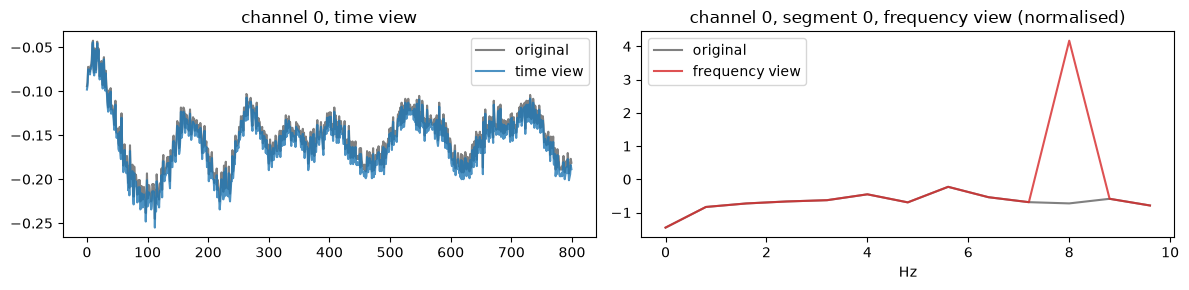

In [20]:
# sanity check: one window, its time view and its frequency view (segment 0, channel 0 shown)
_demo_window = SSLWindowSampler(list(matrices_UNLAB.keys()), matrices_UNLAB, WINDOW_SIZE).sample_one()
_, _tv, _, _fv = make_views(_demo_window[None, :, :])
_spec = to_freq(_demo_window)
_freqs = np.fft.rfftfreq(SEG_LEN, d=RESAMPLING_STEP_S)

fig, axs = plt.subplots(1, 2, figsize=(12, 3))
axs[0].plot(_demo_window[:, 0], color="gray", label="original")
axs[0].plot(_tv[0, :, 0], color="tab:blue", alpha=0.8, label="time view")
axs[0].legend(); axs[0].set_title("channel 0, time view")
axs[1].plot(_freqs, _spec[0, :, 0], color="gray", label="original")
axs[1].plot(_freqs, _fv[0, 0, :, 0], color="tab:red", alpha=0.8, label="frequency view")
axs[1].legend(); axs[1].set_title("channel 0, segment 0, frequency view (normalised)"); axs[1].set_xlabel("Hz")
fig.tight_layout()

## 6. VNet encoders + projection heads

Same `VNet4Levels` architecture as the supervised baseline (copied verbatim), initialised randomly, one instance per domain. The feature used downstream is the **final decoder feature map** (the input of `classifier`, shape `(B, depth, L)`), which keeps the full input resolution. It is mean-pooled inside 1.25 s segments only, never across the whole window:

- time encoder: `L = 800`, pooled with kernel 25 -> 32 segment embeddings
- frequency encoder: `L = 32` (already one step per segment), no pooling -> 32 segment embeddings

A two-layer MLP projector (the paper's `R_T`, `R_F`; 256 -> 128) maps each segment feature `h` to the embedding `z`. `L_T` and `L_F` act on `h`, `L_C` on `z`. The projectors are **kept** for fine-tuning: the classifier reads `[z_T ; z_F]`, as in the paper.

In [21]:
class SpatialDropout1D(nn.Module):
    def __init__(self, p: float = 0.5):
        super(SpatialDropout1D, self).__init__()
        self.dropout = nn.Dropout2d(p)

    def forward(self, x):
        x = x.unsqueeze(3)
        x = self.dropout(x)
        return x.squeeze(3)


class VNet4Levels(nn.Module):
    def __init__(self, in_channels, out_channels, model_depth, dropout_rate=0.5, kernel_size=5):
        super(VNet4Levels, self).__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.depth = model_depth
        self.dropout_rate = dropout_rate
        self.kernel_size = kernel_size

        self.dropout = SpatialDropout1D(p=dropout_rate)

        self.conv1 = self.double_conv(self.in_channels, self.depth)
        self.down1 = nn.Conv1d(self.depth, self.depth * 2, kernel_size=2, stride=2, padding=0)
        self.conv2 = self.double_conv(self.depth * 2, self.depth * 2)

        self.down2 = nn.Conv1d(self.depth * 2, self.depth * 4, kernel_size=2, stride=2, padding=0)
        self.conv3 = self.double_conv(self.depth * 4, self.depth * 4)

        self.down3 = nn.Conv1d(self.depth * 4, self.depth * 8, kernel_size=2, stride=2, padding=0)
        self.conv4 = self.double_conv(self.depth * 8, self.depth * 8)

        self.up1 = self.make_up(self.depth * 8, self.depth * 4)
        self.conv5 = self.double_conv(self.depth * 4, self.depth * 4)

        self.up2 = self.make_up(self.depth * 4, self.depth * 2)
        self.conv6 = self.double_conv(self.depth * 2, self.depth * 2)

        self.up3 = self.make_up(self.depth * 2, self.depth)
        self.conv7 = self.double_conv(self.depth, self.depth)

        self.classifier = nn.Conv1d(self.depth, self.out_channels, kernel_size=1)

    def double_conv(self, in_channels, depth):
        return nn.Sequential(
            nn.Conv1d(in_channels, depth, self.kernel_size, padding=2),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True),
            nn.Conv1d(depth, depth, self.kernel_size, padding=2, bias=False),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True),
        )

    def make_up(self, in_channels, depth):
        return nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv1d(in_channels, depth, kernel_size=3, padding=1),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        conv1 = self.conv1(x)
        conv1_d = self.dropout(conv1)
        down1 = self.down1(conv1_d)
        down1 = F.relu(down1)
        conv2 = self.conv2(down1)
        conv2_d = self.dropout(conv2)

        y = torch.add(down1, conv2_d)
        down2 = self.down2(y)
        down2 = F.relu(down2)
        conv3 = self.conv3(down2)
        conv3_d = self.dropout(conv3)

        y = torch.add(down2, conv3_d)
        down3 = self.down3(y)
        down3 = F.relu(down3)
        conv4 = self.conv4(down3)
        conv4_d = self.dropout(conv4)

        up1 = self.up1(conv4_d)
        y = torch.add(conv3_d, up1)
        pre_conv5 = self.conv5(y)
        pre_conv5_d = self.dropout(pre_conv5)
        conv5 = torch.add(pre_conv5_d, up1)

        up2 = self.up2(conv5)
        y = torch.add(conv2, up2)
        pre_conv6 = self.conv6(y)
        pre_conv6_d = self.dropout(pre_conv6)
        conv6 = torch.add(pre_conv6_d, up2)

        up3 = self.up3(conv6)
        y = torch.add(conv1, up3)
        pre_conv7 = self.conv7(y)
        pre_conv7_d = self.dropout(pre_conv7)
        conv7 = torch.add(pre_conv7_d, up3)

        output = self.classifier(conv7)
        softmax = F.softmax(output, dim=1)
        return softmax

In [22]:
class ProjectionHead(nn.Module):
    """Cross-space projector (TF-C R_T / R_F): two fully-connected layers, feature -> hidden -> embedding, applied to every
    segment feature. Output is NOT normalised (the NT-Xent loss normalises); retained for fine-tuning."""

    def __init__(self, in_dim, hidden_dim=PROJ_HIDDEN_DIM, out_dim=PROJ_OUT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, out_dim),
        )

    def forward(self, x):                      # x: (..., in_dim)
        return self.net(x)


class SegmentCapture:
    """Grabs the VNet's final decoder feature map (input of `classifier`, shape (B, depth, L)) via a
    forward pre-hook, WITHOUT detaching -- gradients flow back through the whole encoder/decoder.
    `segments()` mean-pools it inside non-overlapping blocks of `pool_kernel` steps, so nothing is ever
    averaged over more than one segment: time encoder -> pool_kernel=SEG_LEN, frequency encoder -> 1."""

    def __init__(self, model, pool_kernel):
        self.captured = None
        self.pool_kernel = pool_kernel
        self.handle = model.classifier.register_forward_pre_hook(self._hook)

    def _hook(self, module, inputs):
        self.captured = inputs[0]              # (B, depth, L) -- keeps grad

    def segments(self):
        seg = F.avg_pool1d(self.captured, kernel_size=self.pool_kernel, stride=self.pool_kernel)
        return seg.permute(0, 2, 1)            # (B, N_SEG, depth)

    def remove(self):
        self.handle.remove()

## 7. NT-Xent / InfoNCE loss

NT-Xent is the distance `d` used in all three TF-C terms. For a batch of `N` segment embeddings from each of two views we get `2N` embeddings; the positive of each is the other view of the *same* segment of the *same* window, and the other `2N-2` embeddings are negatives (including other segments of the same window). `nt_xent_loss` L2-normalises its inputs, so cosine similarity is used regardless of the caller. With `SSL_BATCH_SIZE = 64` windows and 32 segments each, `N = 2048` (so each similarity matrix is 4096 x 4096; lower `SSL_BATCH_SIZE` if the device runs out of memory).

In [23]:
def nt_xent_loss(z1, z2, temperature=NTXENT_TEMPERATURE, groups=None):
    """z1, z2: (N, D) (L2-normalised here). groups: optional (N,) window id per row; other rows from the SAME window
    (apart from the positive pair itself) are removed from the negatives."""
    z1, z2 = F.normalize(z1, dim=-1), F.normalize(z2, dim=-1)
    N = z1.shape[0]
    z = torch.cat([z1, z2], dim=0)
    sim = torch.matmul(z, z.T) / temperature

    idx = torch.arange(2 * N, device=z.device)
    positive_idx = (idx + N) % (2 * N)
    mask = torch.eye(2 * N, dtype=torch.bool, device=z.device)
    if groups is not None:
        g = torch.cat([groups, groups])
        same_window = g[:, None] == g[None, :]
        is_positive = idx[None, :] == positive_idx[:, None]
        mask = mask | (same_window & ~is_positive)
    sim = sim.masked_fill(mask, float("-inf"))

    log_prob = F.log_softmax(sim, dim=1)
    return -log_prob[idx, positive_idx].mean()

In [24]:
def tfc_loss(h_t, h_t_aug, h_f, h_f_aug, z_t, z_t_aug, z_f, z_f_aug,
             temperature=NTXENT_TEMPERATURE, lam=TFC_LAMBDA, delta=TFC_DELTA, hinge=TFC_HINGE):
    """TF-C objective (paper Eqs. 1-4) on flattened segment features (N, D):
       L_T = d(h_t, h_t_aug),  L_F = d(h_f, h_f_aug)                      (Eqs. 1, 2; on h)
       L_C = sum_pair (S_TF - S_pair + delta),  pair in {(t,f_aug), (t_aug,f), (t_aug,f_aug)}   (Eq. 3; on z)
             with hinge=True every term is clamped at 0: max(0, S_TF - S_pair + delta). Without it L_C is unbounded below.
       L   = lam * (L_T + L_F) + (1 - lam) * L_C                          (Eq. 4)
    with d = NT-Xent and S_xy = d(z_x, z_y). Shared by pretraining and by the joint fine-tuning loss."""
    l_t = nt_xent_loss(h_t, h_t_aug, temperature)
    l_f = nt_xent_loss(h_f, h_f_aug, temperature)
    s_tf = nt_xent_loss(z_t, z_f, temperature)
    terms = [s_tf - nt_xent_loss(a, b, temperature) + delta
             for a, b in ((z_t, z_f_aug), (z_t_aug, z_f), (z_t_aug, z_f_aug))]
    if hinge:
        terms = [torch.clamp(t, min=0.0) for t in terms]
    l_c = sum(terms)
    loss = lam * (l_t + l_f) + (1 - lam) * l_c
    return loss, (l_t, l_f, l_c)

## 8. TF-C pretraining (time <-> frequency consistency)

Two encoders (`encoder_t`, `encoder_f`), each shared between the original and augmented view of its domain. Both are `VNet4Levels` at half width (`TFC_DEPTH = MODEL_DEPTH // 2`), a thesis design choice (not from the paper) so that the pair has about the parameter count of one full-width encoder. Optimiser: Adam, lr 3e-4, weight decay 5e-4, as in the paper. A fresh set of modules is built for every fold (`make_tfc_modules`). As in the paper, `L_T` and `L_F` are computed on the encoder outputs `h`, and `L_C` on the projected embeddings `z`:

- `L_T = NT-Xent(h_t, h_t_aug)`, `L_F = NT-Xent(h_f, h_f_aug)` (Eqs. 1-2)
- `L_C = Σ max(0, S_TF - S_pair + δ)` over the pairs (t, f_aug), (t_aug, f), (t_aug, f_aug), where `S = NT-Xent` on `z` (Eq. 3 with a hinge when `TFC_HINGE` is set; without it `δ` would only shift the logged value by `3δ`, and `L_C` is unbounded below)
- `L = λ(L_T + L_F) + (1-λ) L_C`, with `λ = TFC_LAMBDA` and `δ = TFC_DELTA`
- Position-shortcut fix (`TFC_ROLL`): every view is circularly rolled by its own random number of whole segments before it enters the encoder (`_embed`), and the segment features are rolled back afterwards so segment *i* of one view still pairs with segment *i* of the other. The encoder therefore cannot match views through absolute position in the window. The encoders use spatial dropout `TFC_PRETRAIN_DROPOUT` during pretraining only.
- Checkpointing and stopping: the epoch loss is noisy because every epoch draws new random windows, so the checkpoint is kept at the best **smoothed** loss (mean of the last `SSL_SMOOTH_WINDOW` epochs) and pretraining stops once that smoothed loss has not improved by `SSL_MIN_DELTA` for `SSL_PATIENCE` epochs, or at `SSL_EPOCHS`. No labels are involved (the paper selects by labelled F1, unavailable here).

In [25]:
# --- TF-C hyperparameters ---------------------------------------------------
TFC_DEPTH = MODEL_DEPTH // 2         # half-width per branch (thesis choice: keeps total parameters near one full-width VNet)
TFC_PROJ_HIDDEN_DIM = PROJ_HIDDEN_DIM
TFC_PROJ_OUT_DIM = PROJ_OUT_DIM
TFC_BATCH_SIZE = SSL_BATCH_SIZE
TFC_WINDOWS_PER_EPOCH = SSL_WINDOWS_PER_EPOCH
TFC_EPOCHS = SSL_EPOCHS
TFC_LR = SSL_LR

memo["TFC_DEPTH"] = TFC_DEPTH
memo["TFC_EPOCHS"] = TFC_EPOCHS



def make_tfc_modules():
    """Fresh randomly-initialised TF-C pretraining modules + optimiser (built once per fold)."""
    encoder_t = VNet4Levels(N_CH, len(CLASSES), TFC_DEPTH, dropout_rate=TFC_PRETRAIN_DROPOUT).to(device)
    encoder_f = VNet4Levels(FREQ_IN_CH, len(CLASSES), TFC_DEPTH, dropout_rate=TFC_PRETRAIN_DROPOUT).to(device)

    # segment embedding = decoder feature map channels (= depth), see SegmentCapture
    proj_head_t = ProjectionHead(TFC_DEPTH, TFC_PROJ_HIDDEN_DIM, TFC_PROJ_OUT_DIM).to(device)
    proj_head_f = ProjectionHead(TFC_DEPTH, TFC_PROJ_HIDDEN_DIM, TFC_PROJ_OUT_DIM).to(device)

    tfc_optimizer = optim.Adam(
        list(encoder_t.parameters()) + list(encoder_f.parameters()) +
        list(proj_head_t.parameters()) + list(proj_head_f.parameters()),
        lr=TFC_LR, weight_decay=SSL_WEIGHT_DECAY,
    )
    return encoder_t, encoder_f, proj_head_t, proj_head_f, tfc_optimizer

In [26]:
class PlateauStopper:
    """Plateau detector on a smoothed loss. update(loss) -> (improved, should_stop).
    `improved` is True when the mean of the last `window` losses beats the best so far by more than `min_delta`;
    `should_stop` is True after `patience` consecutive epochs without such an improvement (never if patience is None)."""

    def __init__(self, patience=None, min_delta=0.0, window=1):
        self.patience, self.min_delta, self.window = patience, min_delta, max(1, window)
        self.raw, self.smoothed = [], []
        self.best, self.best_epoch, self.counter = float("inf"), None, 0

    def update(self, loss):
        self.raw.append(float(loss))
        smooth = float(np.mean(self.raw[-self.window:]))
        self.smoothed.append(smooth)
        improved = smooth < self.best - self.min_delta
        if improved:
            self.best, self.best_epoch, self.counter = smooth, len(self.raw) - 1, 0
        else:
            self.counter += 1
        return improved, (self.patience is not None and self.counter >= self.patience)

In [27]:
class TFCTrainer:
    """Time-frequency consistency pretraining. The objective is `tfc_loss` (paper Eq. 4):
    L = lam * (L_T + L_F) + (1 - lam) * L_C, with L_T / L_F on the encoder features h and L_C on the projected z.
    The checkpoint with the lowest SMOOTHED epoch loss is kept and training stops when that loss plateaus
    (the paper selects by labelled F1, unavailable here).
    roll=True: each of the four views is circularly rolled by its own random number of whole segments before encoding
    and the segment features are rolled back afterwards (see `_embed`). hinge=True: the L_C terms are hinged (see `tfc_loss`).
    """

    def __init__(self, encoder_t, encoder_f, proj_head_t, proj_head_f, optimizer,
                 batch_size, device, save_dir, temperature=NTXENT_TEMPERATURE,
                 lam=TFC_LAMBDA, delta=TFC_DELTA, hinge=TFC_HINGE, roll=TFC_ROLL):
        self.encoder_t, self.encoder_f = encoder_t, encoder_f
        self.proj_head_t, self.proj_head_f = proj_head_t, proj_head_f
        self.optimizer = optimizer
        self.batch_size = batch_size
        self.device = device
        self.temperature = temperature
        self.lam = lam
        self.delta = delta
        self.hinge = hinge
        self.roll = roll
        self.save_dir = Path(save_dir)
        self.save_dir.mkdir(parents=True, exist_ok=True)
        self.best_loss = float("inf")      # best smoothed epoch loss
        self.best_epoch = None             # 0-based epoch of the saved checkpoint
        self.stopped_early = False
        self.train_losses = []
        self.smooth_losses = []
        self.loss_parts = {"L_T": [], "L_F": [], "L_C": []}
        self.total_duration = 0

    def _embed(self, encoder, capture, proj_head, x, k=0, is_time=True):
        """k > 0: roll the INPUT circularly by k whole segments (k * SEG_LEN steps for the time encoder, k steps for the
        frequency encoder), encode, then roll the segment features back by -k so that row i is again segment i of the
        original window. The encoder sees different absolute positions in each view; the segment pairing is unchanged."""
        if k:
            x = torch.roll(x, shifts=k * (SEG_LEN if is_time else 1), dims=2)
        _ = encoder(x)
        h = capture.segments()                      # (B, N_SEG, depth)
        z = proj_head(h)                            # (B, N_SEG, PROJ_OUT_DIM)
        if k:
            h, z = torch.roll(h, shifts=-k, dims=1), torch.roll(z, shifts=-k, dims=1)
        return h.reshape(-1, h.shape[-1]), z.reshape(-1, z.shape[-1])

    def train(self, ssl_generator, epochs, batch_size=None, patience=None, min_delta=0.0,
              smooth_window=1, log_every=1):
        batch_size = batch_size or self.batch_size
        capture_t = SegmentCapture(self.encoder_t, pool_kernel=SEG_LEN)
        capture_f = SegmentCapture(self.encoder_f, pool_kernel=1)
        stopper = PlateauStopper(patience, min_delta, smooth_window)

        try:
            for epoch in range(epochs):
                t0 = time.time()
                for m in (self.encoder_t, self.encoder_f, self.proj_head_t, self.proj_head_f):
                    m.train(True)

                X_ep = next(ssl_generator)   # (windows_per_epoch, WINDOW_SIZE, C) raw windows
                n_batches = int(np.ceil(len(X_ep) / batch_size))
                epoch_loss = epoch_lt = epoch_lf = epoch_lc = 0.0
                perm = np.random.permutation(len(X_ep))

                for b in range(n_batches):
                    idx = perm[b * batch_size:(b + 1) * batch_size]
                    if len(idx) < 2:
                        continue
                    x_t_np, x_t_aug_np, x_f_np, x_f_aug_np = make_views(X_ep[idx])
                    x_t = torch.tensor(x_t_np, dtype=torch.float32, device=self.device).permute(0, 2, 1)
                    x_t_aug = torch.tensor(x_t_aug_np, dtype=torch.float32, device=self.device).permute(0, 2, 1)
                    x_f = freq_to_tensor(x_f_np, self.device)
                    x_f_aug = freq_to_tensor(x_f_aug_np, self.device)

                    self.optimizer.zero_grad()
                    ks = np.random.randint(0, N_SEG, size=4) if self.roll else (0, 0, 0, 0)   # independent roll per view
                    ht, zt = self._embed(self.encoder_t, capture_t, self.proj_head_t, x_t, int(ks[0]), True)
                    ht_aug, zt_aug = self._embed(self.encoder_t, capture_t, self.proj_head_t, x_t_aug, int(ks[1]), True)
                    hf, zf = self._embed(self.encoder_f, capture_f, self.proj_head_f, x_f, int(ks[2]), False)
                    hf_aug, zf_aug = self._embed(self.encoder_f, capture_f, self.proj_head_f, x_f_aug, int(ks[3]), False)

                    loss, (l_t, l_f, l_c) = tfc_loss(ht, ht_aug, hf, hf_aug, zt, zt_aug, zf, zf_aug,
                                                     self.temperature, self.lam, self.delta, self.hinge)

                    loss.backward()
                    self.optimizer.step()
                    epoch_loss += loss.item()
                    epoch_lt += l_t.item()
                    epoch_lf += l_f.item()
                    epoch_lc += l_c.item()

                epoch_loss /= n_batches
                epoch_lt /= n_batches
                epoch_lf /= n_batches
                epoch_lc /= n_batches
                self.train_losses.append(epoch_loss)
                self.loss_parts["L_T"].append(epoch_lt)
                self.loss_parts["L_F"].append(epoch_lf)
                self.loss_parts["L_C"].append(epoch_lc)
                duration = time.time() - t0
                self.total_duration += duration

                improved, should_stop = stopper.update(epoch_loss)
                self.smooth_losses = stopper.smoothed
                if improved:
                    self.best_loss, self.best_epoch = stopper.best, epoch
                    torch.save(self.encoder_t.state_dict(), self.save_dir / "encoder_t_pretrained.pth")
                    torch.save(self.encoder_f.state_dict(), self.save_dir / "encoder_f_pretrained.pth")
                    torch.save(self.proj_head_t.state_dict(), self.save_dir / "proj_head_t.pth")
                    torch.save(self.proj_head_f.state_dict(), self.save_dir / "proj_head_f.pth")

                if epoch == 0 or (epoch + 1) % log_every == 0:
                    print(f"[TF-C] Epoch {epoch+1}/{epochs}  L={epoch_loss:.4f}  smoothed={stopper.smoothed[-1]:.4f}  "
                          f"(L_T={epoch_lt:.3f} L_F={epoch_lf:.3f} L_C={epoch_lc:.3f})  "
                          f"best@{self.best_epoch + 1}  patience {stopper.counter}/{patience}  ({duration:.1f}s)")

                if should_stop:
                    self.stopped_early = True
                    print(f"[TF-C] Epoch {epoch+1}: smoothed loss has not improved for {patience} epochs, stopping "
                          f"(best smoothed loss {self.best_loss:.4f} at epoch {self.best_epoch + 1}).")
                    break
        finally:
            capture_t.remove()
            capture_f.remove()

## 9. Fine-tuning setup

From here on we are back on the fold's TRAIN / VAL / TEST recordings only. Training windows come from the class-balanced generator below (`Global_generator`, reused verbatim from the supervised notebook); the loss is cross-entropy weighted by the per-class `loss_weight`. Validation and test sets are built by one shared function so they match (section 10).

In [28]:
def density_for_one_promotion(turtle_name, CLASS):
    label = labels[turtle_name]
    N = len(label)
    dens = np.zeros_like(label)
    dens[label == CLASS.id] = 1

    sum_dens = np.sum(dens)
    if sum_dens < 1e-6:
        dens[:] = 1
        sum_dens = len(dens)
    dens /= sum_dens

    kernel = np.ones(int(1.5 * WINDOW_SIZE))
    kernel /= np.sum(kernel)
    dens_conv = np.convolve(dens, kernel, mode='same')
    dens_conv[-WINDOW_SIZE // 2 - 2:] = 0
    dens_conv[:WINDOW_SIZE // 2 + 2] = 0

    cdf = np.cumsum(dens_conv)
    cdf /= cdf[-1]

    def rand_gene():
        while True:
            yield np.argmax(cdf > np.random.random()) - WINDOW_SIZE // 2

    return dens, dens_conv, cdf, rand_gene()


class InterestingTurtles:
    def __init__(self, turtle_names, CLASS):
        self.turtle_names = turtle_names
        self.occurences = np.zeros(len(turtle_names))
        self.CLASS = CLASS
        for i, name in enumerate(turtle_names):
            self.occurences[i] += np.sum(labels[name] == CLASS.id)
        total = np.sum(self.occurences)
        # LOOCV: a class can be absent from a fold's training recordings -> uniform (never used, see Global_generator)
        self.proba = self.occurences / total if total > 0 else np.full(len(turtle_names), 1.0 / len(turtle_names))

    def give_me_one_turtle(self):
        return np.random.choice(a=self.turtle_names, p=self.proba)


class Global_generator:
    def __init__(self, turtle_names):
        self.turtle_names = turtle_names
        self.interesting_turtles_by_class = {}
        self.proba_of_classes = np.zeros(len(CLASSES))

        for CLASS in CLASSES:
            self.interesting_turtles_by_class[CLASS.name] = InterestingTurtles(turtle_names, CLASS)
            self.proba_of_classes[CLASS.id] = CLASS.sampling_weight
            if self.interesting_turtles_by_class[CLASS.name].occurences.sum() == 0:
                self.proba_of_classes[CLASS.id] = 0.0   # class absent from this fold's training recordings: never sampled
        self.proba_of_classes /= np.sum(self.proba_of_classes)

        self.class_2_index_gene = {}
        for CLASS in CLASSES:
            random_index_generators = {}
            for name in turtle_names:
                _, _, _, gene = density_for_one_promotion(name, CLASS)
                random_index_generators[name] = gene
            self.class_2_index_gene[CLASS.name] = random_index_generators

    def give_me_turtle_and_timeIndex(self):
        if np.random.rand() < 0.1:
            theTurtle = np.random.choice(self.turtle_names)
            deb = 0
            fin = len(labels[theTurtle]) - WINDOW_SIZE
            t = np.random.randint(deb, fin)
            return theTurtle, t

        theClass = np.random.choice(CLASSES, p=self.proba_of_classes)
        theTurtle = self.interesting_turtles_by_class[theClass.name].give_me_one_turtle()
        theGenerators = self.class_2_index_gene[theClass.name]
        theGenerator = theGenerators[theTurtle]
        return theTurtle, next(theGenerator)


def oneEpoch_generator_window(turtle_names, size=100):
    generator = Global_generator(turtle_names)
    while True:
        X = np.empty([size, WINDOW_SIZE, len(DESCRIPTORS_SELEC)])
        Y = np.empty([size, WINDOW_SIZE], dtype=int)
        for i in range(size):
            turtle_name, t = generator.give_me_turtle_and_timeIndex()
            matrix = matrices[turtle_name]
            label = labels[turtle_name]
            X[i, :, :] = matrix[t:t + WINDOW_SIZE, :]
            Y[i, :] = label[t:t + WINDOW_SIZE]
        yield X, Y

In [29]:
ponde = torch.tensor(np.array([CLASS.loss_weight for CLASS in CLASSES], dtype=np.float32))
ponde /= torch.sum(ponde)
ponde

tensor([0.0123, 0.1235, 0.2469, 0.1235, 0.1235, 0.2469, 0.1235])

In [30]:
memo["nb_train_per_epoch"] = 10000

## 10. Downstream classifier (per 1.25 s segment)

Following TF-C, the pretrained encoders and projectors feed a 2-layer MLP head (hidden 64). Each 1.25 s segment is classified from `[z_T ; z_F]`, the concatenation of its time and frequency embeddings, so one 40 s window gives 32 predictions. The paper (Appendix E) optimises the TF-C loss jointly with the classification loss during fine-tuning; this is available through `FT_TFC_AUX_WEIGHT` but is off (0) in the final run, following the diagnostics (when on, its auxiliary views are not rolled). The label of a segment is the majority class among its 25 timesteps. Everything is fine-tuned end to end (encoders, projectors and head all train; optimiser settings as in pretraining), and the best-validation checkpoint is restored at the end of training (early stopping with `FINETUNE_PATIENCE`).

Validation and test sets are built by the same function, `build_eval_set`: non-overlapping 40 s windows taken in order from each recording, no class balancing.

In [31]:
def segment_labels(Y):
    """Y: (N, WINDOW_SIZE) per-timestep labels -> (N, N_SEG) majority class of each 1.25 s segment."""
    segs = Y.reshape(len(Y), N_SEG, SEG_LEN)
    counts = (segs[..., None] == np.arange(len(CLASSES))).sum(axis=2)    # (N, N_SEG, n_classes)
    return counts.argmax(axis=2).astype(int)


def oneEpoch_generator_segments(turtle_names, size=100):
    """Same class-balanced window sampling as `oneEpoch_generator_window`, with labels collapsed to
    one majority-vote label per 1.25 s segment."""
    base_gen = oneEpoch_generator_window(turtle_names, size=size)
    while True:
        X, Y = next(base_gen)
        yield X, segment_labels(Y)


def cut_full_slice(matrix, label):
    """Non-overlapping WINDOW_SIZE slices of one recording -> X (n, WINDOW_SIZE, C), y (n, N_SEG)."""
    n = len(matrix) // WINDOW_SIZE
    X = matrix[:n * WINDOW_SIZE].reshape(n, WINDOW_SIZE, matrix.shape[1])
    Y = label[:n * WINDOW_SIZE].reshape(n, WINDOW_SIZE)
    return X, segment_labels(Y)


def build_eval_set(names):
    """Shared by validation and test so the two sets are constructed identically."""
    Xs, ys = zip(*[cut_full_slice(matrices[name], labels[name]) for name in names])
    return np.concatenate(Xs), np.concatenate(ys)

In [32]:
class TFCClassifier(nn.Module):
    """Pretrained TF-C model (G_T, R_T, G_F, R_F) + classifier on [z_T ; z_F] (paper Sec. 4.4), one prediction per 1.25 s
    segment. Full fine-tune: encoders, projectors and head all train. forward(..., with_aux=True) also returns the
    TF-C loss of the batch, to be optimised jointly with the classification loss."""

    def __init__(self, encoder_t, encoder_f, proj_t, proj_f, num_classes, hidden_dim=FT_HEAD_HIDDEN):
        super().__init__()
        self.encoder_t, self.encoder_f = encoder_t, encoder_f
        self.proj_t, self.proj_f = proj_t, proj_f
        self.capture_t = SegmentCapture(self.encoder_t, pool_kernel=SEG_LEN)
        self.capture_f = SegmentCapture(self.encoder_f, pool_kernel=1)

        self.head = nn.Sequential(
            nn.Linear(2 * TFC_PROJ_OUT_DIM, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(DROPOUT),
            nn.Linear(hidden_dim, num_classes),
        )

    def _hz(self, encoder, capture, proj, x):
        _ = encoder(x)
        h = capture.segments()                      # (B, N_SEG, depth)
        return h, proj(h)                           # z: (B, N_SEG, PROJ_OUT_DIM)

    def forward(self, x_time, with_aux=False):
        # x_time: (B, C, WINDOW_SIZE) -- same layout the VNet encoders already expect
        x_time = x_time.contiguous()
        dev = x_time.device
        x_np = x_time.permute(0, 2, 1).detach().cpu().numpy()
        if with_aux:
            _, xa_np, f_np, fa_np = make_views(x_np)
        else:
            f_np = np.stack([to_freq(w) for w in x_np])
        x_freq = freq_to_tensor(f_np, dev)

        h_t, z_t = self._hz(self.encoder_t, self.capture_t, self.proj_t, x_time)
        h_f, z_f = self._hz(self.encoder_f, self.capture_f, self.proj_f, x_freq)
        logits = self.head(torch.cat([z_t, z_f], dim=2))                 # (B, N_SEG, num_classes)
        if not with_aux:
            return logits

        x_aug = torch.tensor(xa_np, dtype=torch.float32, device=dev).permute(0, 2, 1)
        x_freq_aug = freq_to_tensor(fa_np, dev)
        h_ta, z_ta = self._hz(self.encoder_t, self.capture_t, self.proj_t, x_aug)
        h_fa, z_fa = self._hz(self.encoder_f, self.capture_f, self.proj_f, x_freq_aug)
        flat = lambda a: a.reshape(-1, a.shape[-1])
        aux, _ = tfc_loss(flat(h_t), flat(h_ta), flat(h_f), flat(h_fa),
                          flat(z_t), flat(z_ta), flat(z_f), flat(z_fa))
        return logits, aux

    def remove_hooks(self):
        self.capture_t.remove()
        self.capture_f.remove()


def build_tfc_classifier(pretrained=True, pretrain_dir=None):
    """pretrain_dir: folder holding the fold's pretrained encoder/projector weights (required if pretrained)."""
    assert not pretrained or pretrain_dir is not None, "pass the fold's pretrain_dir"
    et = VNet4Levels(N_CH, len(CLASSES), TFC_DEPTH, dropout_rate=DROPOUT)
    ef = VNet4Levels(FREQ_IN_CH, len(CLASSES), TFC_DEPTH, dropout_rate=DROPOUT)
    pt = ProjectionHead(TFC_DEPTH, TFC_PROJ_HIDDEN_DIM, TFC_PROJ_OUT_DIM)
    pf = ProjectionHead(TFC_DEPTH, TFC_PROJ_HIDDEN_DIM, TFC_PROJ_OUT_DIM)
    if pretrained:
        for module, fname in ((et, "encoder_t_pretrained.pth"), (ef, "encoder_f_pretrained.pth"),
                              (pt, "proj_head_t.pth"), (pf, "proj_head_f.pth")):
            module.load_state_dict(torch.load(Path(pretrain_dir) / fname, weights_only=True, map_location="cpu"))
    et, ef, pt, pf = et.to(device), ef.to(device), pt.to(device), pf.to(device)
    return TFCClassifier(et, ef, pt, pf, num_classes=len(CLASSES)).to(device)

In [33]:
def predict_logits(model, X, batch_size=128):
    """X: (n, WINDOW_SIZE, C) numpy -> logits (n, N_SEG, n_classes), computed in chunks."""
    model.train(False)
    dev = next(model.parameters()).device
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = torch.from_numpy(np.ascontiguousarray(X[i:i + batch_size])).float().permute(0, 2, 1).to(dev)
            out.append(model(xb))
    return torch.cat(out)


def train_tfc_classifier(model, train_gen, X_val, y_val, epochs, lr, class_weights,
                         device, save_dir, patience=FINETUNE_PATIENCE, weight_decay=FINETUNE_WEIGHT_DECAY,
                         batch_size=FINETUNE_BATCH_SIZE, aux_weight=FT_TFC_AUX_WEIGHT, log_every=LOG_EVERY):
    save_dir = Path(save_dir); save_dir.mkdir(parents=True, exist_ok=True)
    n_cls = len(CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    y_val_t = torch.from_numpy(y_val).long().reshape(-1).to(device)

    best_loss, counter = float("inf"), 0
    history = {"train_loss": [], "train_aux": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        t0 = time.time()
        model.train(True)
        X_ep, y_ep = next(train_gen)
        X_ep_t = torch.from_numpy(X_ep).float().permute(0, 2, 1)
        y_ep_t = torch.from_numpy(y_ep).long()
        loader = torch.utils.data.DataLoader(
            torch.utils.data.TensorDataset(X_ep_t, y_ep_t), batch_size=batch_size, shuffle=True)

        total_loss = total_aux = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            if aux_weight > 0:
                logits, aux = model(xb, with_aux=True)                # logits (B, N_SEG, n_cls), aux = TF-C loss
            else:
                logits, aux = model(xb), torch.zeros((), device=device)
            ce = criterion(logits.reshape(-1, n_cls), yb.reshape(-1))
            (ce + aux_weight * aux).backward()
            optimizer.step()
            total_loss += ce.item()
            total_aux += aux.item()
        train_loss = total_loss / len(loader)
        train_aux = total_aux / len(loader)

        val_logits = predict_logits(model, X_val).reshape(-1, n_cls)
        val_loss = criterion(val_logits, y_val_t).item()
        val_acc = (val_logits.argmax(dim=1) == y_val_t).float().mean().item()

        history["train_loss"].append(train_loss)
        history["train_aux"].append(train_aux)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if epoch == 0 or (epoch + 1) % log_every == 0:
            print(f"[TF-C clf] Epoch {epoch+1}/{epochs}  train_ce={train_loss:.4f}  tfc_aux={train_aux:.3f}  "
              f"val_loss={val_loss:.4f}  val_acc={val_acc:.4f}  ({time.time()-t0:.1f}s)")

        if val_loss < best_loss:
            best_loss = val_loss
            torch.save(model.state_dict(), save_dir / "tfc_classifier.pth")
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                print(f"[TF-C clf] Epoch {epoch+1}: early stopping, no val_loss improvement for {patience} epochs "
                      f"(best val_loss={best_loss:.4f})")
                break

    # restore the best-validation weights, so the model evaluated afterwards is the checkpoint early stopping selected
    model.load_state_dict(torch.load(save_dir / "tfc_classifier.pth", weights_only=True, map_location=device))
    return history

## 11. Evaluation utilities

The held-out individual's test set comes from `build_eval_set`, the same construction as the validation set. Predictions are per 1.25 s segment and scored with `build_metrics_table` (per-class accuracy / recall / precision / specificity / F1 from the confusion matrix). Macro F1 is the mean over the classes present in the ground truth; the headline LOOCV number excludes `Other`, as in the supervised LOOCV notebook.

In [34]:
def build_metrics_table(y_true, y_pred, class_names):
    """FIX: the previous version divided TP/(TP+FN) etc. directly, so a class that is never
    predicted (FP+TP=0) gave 0/0 = NaN, silently dropped by np.nanmean downstream and inflating
    the reported macro F1. This version returns 0 instead of NaN for an undefined ratio, and adds
    a Support column so macro_f1() below can average only over classes actually present."""
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    TP = np.diag(cm).astype(float)
    FN = cm.sum(axis=1) - TP
    FP = cm.sum(axis=0) - TP
    TN = cm.sum() - TP - FP - FN

    def div(a, b):
        return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b > 0)

    df = pd.DataFrame({
        "Accuracy": (TP + TN) / cm.sum(),
        "Recall": div(TP, TP + FN),
        "Precision": div(TP, TP + FP),
        "Specificity": div(TN, TN + FP),
        "Support": cm.sum(axis=1),
    }, index=class_names)
    df["F1_score"] = div(2 * TP, 2 * TP + FP + FN)
    return df


def macro_f1(df, exclude=()):
    """Mean F1 over classes with Support > 0 (present in y_true), excluding any names in `exclude`.
    A present class that is never predicted correctly now scores 0 and pulls the mean down,
    instead of being dropped as NaN."""
    d = df[(df["Support"] > 0) & (~df.index.isin(exclude))]
    return float(d["F1_score"].mean())


class_names = [CLASS.name for CLASS in CLASSES]

In [35]:
def evaluate_tfc(model, X_test, y_test, label, verbose=False):
    """Score a model on a held-out set (as built by build_eval_set). Returns (metrics table, per-segment predictions)."""
    pred = predict_logits(model, X_test).argmax(dim=2).cpu().numpy()
    df = build_metrics_table(y_test.reshape(-1), pred.reshape(-1), class_names)
    excl_other = macro_f1(df, exclude=("Other",))
    print(f"  {label}: test macro-F1 excluding Other = {excl_other:.4f} | all present classes = {macro_f1(df):.4f}")
    if verbose:
        share = np.bincount(pred.reshape(-1), minlength=len(class_names)) / pred.size
        print("  predicted-class share:", dict(zip(class_names, np.round(share, 3))))
        display(df)
    return df, pred

In [36]:
def cut_full_slice_overlap(matrix, label):
    """Overlapping windows of one recording (same as B_bis `cut_full_slice`): X (n, WINDOW_SIZE, C), Y (n, WINDOW_SIZE)."""
    margin = int(0.1 * WINDOW_SIZE)
    stride = WINDOW_SIZE - 2 * margin
    size = len(matrix) // stride - 1
    X = np.empty([size, WINDOW_SIZE, matrix.shape[1]])
    Y = np.empty([size, WINDOW_SIZE], dtype=int)
    for i in range(size):
        t = i * stride
        X[i, :, :] = matrix[t:t + WINDOW_SIZE, :]
        Y[i] = label[t:t + WINDOW_SIZE]
    return X, Y


def stick(Y):
    """Stitch overlapping windows back into one sequence, dropping the margins (same as B_bis `stick`)."""
    window_size = Y.shape[1]
    margin = int(0.1 * window_size)
    res = [Y[0, :window_size - margin]]
    for i in range(1, len(Y)):
        res.append(Y[i, margin:-margin])
    return np.concatenate(res, axis=0)


def evaluate_tfc_stitched(model, names, label, verbose=False):
    """Per-timestep metrics on the held-out recordings `names`, scored like B_bis `evaluate_names`.
    Returns (metrics table, stitched y_true, stitched y_pred); the table works with `macro_f1` and `per_class_f1`."""
    all_true, all_pred = [], []
    for name in names:
        X_cut, Y_cut = cut_full_slice_overlap(matrices[name], labels[name])
        seg_pred = predict_logits(model, X_cut).argmax(dim=2).cpu().numpy()      # (n, N_SEG), one class per 1.25 s
        Y_pred = np.repeat(seg_pred, SEG_LEN, axis=1)                             # (n, WINDOW_SIZE), one class per timestep
        all_true.append(stick(Y_cut))
        all_pred.append(stick(Y_pred))
    y_true, y_pred = np.concatenate(all_true), np.concatenate(all_pred)

    df = build_metrics_table(y_true, y_pred, class_names)
    print(f"  {label}: test macro-F1 excluding Other = {macro_f1(df, exclude=('Other',)):.4f} "
          f"(per timestep, stitched like the supervised LOOCV) | all present classes = {macro_f1(df):.4f}")
    if verbose:
        share = np.bincount(y_pred, minlength=len(class_names)) / y_pred.size
        print("  predicted-class share:", dict(zip(class_names, np.round(share, 3))))
        display(df)
    return df, y_true, y_pred

## 12. Leave-one-individual-out cross-validation loop

For every individual: hold out all of its recordings as the test set, pick `N_VAL_INDIVIDUALS_PER_FOLD` of the *remaining* individuals for validation (same seeds as the supervised LOOCV, so the folds match), and run the full pipeline of sections 2-11 on the rest:

1. build the pretraining pool from the fold's TRAIN recordings + all unlabelled recordings and re-fit the frequency standardisation on it,
2. TF-C pretraining from random initialisation (until the smoothed loss plateaus, at most `SSL_EPOCHS`),
3. full end-to-end fine-tuning with early stopping on the fold's validation individuals (at most `FINETUNE_EPOCHS`), best checkpoint restored,
4. the same fine-tuning from random initialisation (`RUN_SCRATCH_CONTROL`), as the control,
5. evaluation of both on the held-out individual.

The pretraining is repeated in every fold because its pool contains the fold's labelled TRAIN recordings, which differ from fold to fold. Results are written after every fold (`fold_result.json`, `loocv_f1_summary.csv`), so an interrupted run can be continued by setting `RESUME_DIR`.

In [37]:
def class_balance(names):
    """Total number of timesteps per class across the given recordings."""
    counts = np.zeros(len(CLASSES), dtype=np.int64)
    for name in names:
        lab = labels[name]
        for CLASS in CLASSES:
            counts[CLASS.id] += np.sum(lab == CLASS.id)
    return pd.Series(counts, index=class_names, name="n_timesteps")


def split_fold(fold_idx, test_individual):
    """Same split rule as the supervised LOOCV notebook (identical seeds -> identical folds)."""
    remaining = [i for i in INDIVIDUAL_IDS if i != test_individual]
    rng = np.random.RandomState(fold_idx)            # reproducible train/val split per fold
    shuffled = [str(i) for i in rng.permutation(remaining)]
    val_inds = shuffled[:N_VAL_INDIVIDUALS_PER_FOLD]
    train_inds = shuffled[N_VAL_INDIVIDUALS_PER_FOLD:]
    return {
        "test": INDIVIDUAL_TO_NAMES[test_individual],
        "val": [n for i in val_inds for n in INDIVIDUAL_TO_NAMES[i]],
        "train": [n for i in train_inds for n in INDIVIDUAL_TO_NAMES[i]],
        "val_individuals": val_inds,
        "train_individuals": train_inds,
    }


def finetune_summary(history, max_epochs):
    """(epochs run, best epoch (1-based), stopped early?, best val_loss) from a fine-tuning history."""
    n = len(history["val_loss"])
    best = int(np.argmin(history["val_loss"]))
    return n, best + 1, n < max_epochs, float(history["val_loss"][best])


def per_class_f1(df):
    """Per-class F1 with classes absent from the held-out individual set to NaN (not scored)."""
    return df["F1_score"].where(df["Support"] > 0)


def free_device_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        torch.xpu.empty_cache()


def plot_fold_curves(trainer, hist_ft, hist_sc, title, save_path):
    fig, axs = plt.subplots(1, 3, figsize=(17, 4))
    axs[0].plot(trainer.train_losses, color="lightgray", label="epoch loss")
    axs[0].plot(trainer.smooth_losses, color="tab:blue", label=f"smoothed ({SSL_SMOOTH_WINDOW} ep)")
    if trainer.best_epoch is not None:
        axs[0].axvline(trainer.best_epoch, color="coral", linestyle="--", label=f"checkpoint (epoch {trainer.best_epoch + 1})")
    axs[0].set_title("TF-C pretraining loss"); axs[0].legend()
    for ax, hist, name in ((axs[1], hist_ft, "fine-tune (pretrained)"), (axs[2], hist_sc, "fine-tune (random init)")):
        if hist is None:
            ax.set_visible(False)
            continue
        ax.plot(hist["train_loss"], label="train CE"); ax.plot(hist["val_loss"], label="val CE")
        ax.axvline(int(np.argmin(hist["val_loss"])), color="coral", linestyle="--", label="best val")
        ax.set_title(name); ax.legend()
    for ax in axs:
        ax.set_xlabel("epoch")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(save_path)
    plt.show()

In [38]:
def run_fold(fold_idx, test_individual, fold_dir):
    """One LOOCV fold: split -> pool -> TF-C pretraining -> fine-tune (pretrained) -> fine-tune (random init control) -> test."""
    set_seed(SEED + fold_idx)
    os.makedirs(fold_dir, exist_ok=True)
    sp = split_fold(fold_idx, test_individual)
    names_train, names_val, names_test = sp["train"], sp["val"], sp["test"]

    print(f"\n===== Fold {fold_idx+1}/{len(INDIVIDUAL_IDS)} | held-out individual: {test_individual} "
          f"({len(names_test)} recording(s)) =====")
    print("  train individuals:", sp["train_individuals"], "->", names_train)
    print("  val individuals  :", sp["val_individuals"], "->", names_val)

    train_balance = class_balance(names_train)
    print("  training class balance (timesteps):")
    print(train_balance.to_string())
    missing = train_balance[train_balance == 0].index.tolist()
    if missing:
        print(f"  WARNING: {missing} have ZERO training examples in this fold -> the model cannot learn them "
              f"and will never predict them for {test_individual}.")

    # ---- 1) pretraining pool (fold TRAIN + unlabelled) and the frequency standardisation fitted on it -------------
    pool_names, pool_matrices, pool_hours, labelled_hours = build_pool(names_train)
    print(f"  pretraining pool: {len(pool_names)} recordings, {pool_hours:.1f} h "
          f"({labelled_hours:.1f} h labelled + {pool_hours - labelled_hours:.1f} h unlabelled)")
    refit_freq_norm(pool_names, pool_matrices)

    # ---- 2) TF-C pretraining ------------------------------------------------------------------------------------
    pre_dir = os.path.join(fold_dir, "pretrain")
    encoder_t, encoder_f, proj_head_t, proj_head_f, tfc_optimizer = make_tfc_modules()
    trainer = TFCTrainer(encoder_t, encoder_f, proj_head_t, proj_head_f, tfc_optimizer,
                         TFC_BATCH_SIZE, device, save_dir=pre_dir)
    tfc_gen = ssl_epoch_generator(pool_names, pool_matrices, WINDOW_SIZE, size=TFC_WINDOWS_PER_EPOCH)
    trainer.train(tfc_gen, epochs=TFC_EPOCHS, patience=SSL_PATIENCE, min_delta=SSL_MIN_DELTA,
                  smooth_window=SSL_SMOOTH_WINDOW, log_every=LOG_EVERY)
    print(f"  -> pretraining took {trainer.total_duration/60:.1f} min over {len(trainer.train_losses)} epoch(s)")
    del encoder_t, encoder_f, proj_head_t, proj_head_f, tfc_optimizer, tfc_gen
    free_device_memory()

    # ---- 3) fine-tuning data: the fold's own VAL individuals and the held-out TEST individual -------------------
    X_val, y_val = build_eval_set(names_val)
    X_test, y_test = build_eval_set(names_test)
    print(f"  validation set: {X_val.shape[0]} windows -> {y_val.size} segments | "
          f"test set: {X_test.shape[0]} windows -> {y_test.size} segments")

    # ---- 4) full fine-tune from the pretrained weights ---------------------------------------------------------
    model_ft = build_tfc_classifier(pretrained=True, pretrain_dir=pre_dir)
    hist_ft = train_tfc_classifier(
        model_ft, oneEpoch_generator_segments(names_train, size=memo["nb_train_per_epoch"]), X_val, y_val,
        epochs=FINETUNE_EPOCHS, lr=FINETUNE_LR, class_weights=ponde, device=device,
        save_dir=os.path.join(fold_dir, "finetune"), patience=FINETUNE_PATIENCE, log_every=LOG_EVERY)
    df_ft, y_true_st, pred_ft = evaluate_tfc_stitched(model_ft, names_test, "TF-C pretrained + full fine-tune")
    model_ft.remove_hooks()
    del model_ft
    free_device_memory()

    # ---- 5) control: identical pipeline, random init ------------------------------------------------------------
    hist_sc, df_sc, pred_sc = None, None, None
    if RUN_SCRATCH_CONTROL:
        model_sc = build_tfc_classifier(pretrained=False)
        hist_sc = train_tfc_classifier(
            model_sc, oneEpoch_generator_segments(names_train, size=memo["nb_train_per_epoch"]), X_val, y_val,
            epochs=FINETUNE_EPOCHS, lr=FINETUNE_LR, class_weights=ponde, device=device,
            save_dir=os.path.join(fold_dir, "scratch"), patience=FINETUNE_PATIENCE, log_every=LOG_EVERY)
        df_sc, _, pred_sc = evaluate_tfc_stitched(model_sc, names_test, "random init (control)")

        model_sc.remove_hooks()
        del model_sc
        free_device_memory()

    plot_fold_curves(trainer, hist_ft, hist_sc, f"Held-out {test_individual}", os.path.join(fold_dir, "curves.png"))

    preds = {"y_true": y_true_st, "pred_pretrained": pred_ft}
    if pred_sc is not None:
        preds["pred_scratch"] = pred_sc
    np.savez_compressed(os.path.join(fold_dir, "test_predictions.npz"), **preds)

    n_ft, best_ft, early_ft, bvl_ft = finetune_summary(hist_ft, FINETUNE_EPOCHS)
    res = {
        "fold": fold_idx + 1,
        "test_individual": test_individual,
        "n_test_recordings": len(names_test),
        "n_train_individuals": len(sp["train_individuals"]),
        "n_val_individuals": len(sp["val_individuals"]),
        "pretrain_epochs_run": len(trainer.train_losses),
        "pretrain_best_epoch": int(trainer.best_epoch) + 1,
        "pretrain_stopped_early": bool(trainer.stopped_early),
        "pretrain_best_smoothed_loss": float(trainer.best_loss),
        "pretrain_duration_s": float(trainer.total_duration),
        "ft_epochs_run": n_ft, "ft_best_epoch": best_ft, "ft_stopped_early": bool(early_ft), "ft_best_val_loss": bvl_ft,
        "macro_F1": macro_f1(df_ft, exclude=("Other",)),          # headline: pretrained, excluding Other
        "macro_F1_all_classes": macro_f1(df_ft),
    }
    pcf = pd.DataFrame({"pretrained": per_class_f1(df_ft)})
    if df_sc is not None:
        n_sc, best_sc, early_sc, bvl_sc = finetune_summary(hist_sc, FINETUNE_EPOCHS)
        res.update({
            "scratch_epochs_run": n_sc, "scratch_best_epoch": best_sc, "scratch_stopped_early": bool(early_sc),
            "scratch_best_val_loss": bvl_sc,
            "macro_F1_scratch": macro_f1(df_sc, exclude=("Other",)),
            "macro_F1_scratch_all_classes": macro_f1(df_sc),
        })
        pcf["scratch"] = per_class_f1(df_sc)
    res.update({f"train_n_{c}": int(train_balance[c]) for c in class_names})

    print(f"  -> fold {fold_idx+1} macro-F1 (excl. Other): pretrained {res['macro_F1']:.4f}"
          + (f" | random init {res['macro_F1_scratch']:.4f}" if df_sc is not None else ""))

    del trainer
    free_device_memory()
    return res, pcf


===== Fold 1/14 | held-out individual: CC-07-107_11-02-2019 (1 recording(s)) =====
  train individuals: ['CC-07-48_06-10-2018', 'CC-07-48_26-05-2018', 'CC-07-47_14-02-2018', 'CC-07-48_18-02-2019', 'CC-07-115_13-05-2019+14-05-2019', 'CC-07-48_10-10-2018', 'CC-07-48_22-05-2018', 'CC-07-48_04-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_08-04-2019', 'CC-09-72_04-11-2022'] -> ['CC-07-48_06-10-2018', 'CC-07-48_26-05-2018', 'CC-07-47_14-02-2018', 'CC-07-48_18-02-2019', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_10-10-2018', 'CC-07-48_22-05-2018', 'CC-07-48_04-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-09-72_04-11-2022']
  val individuals  : ['CC-07-48_08-10-2018', 'CC-07-59_20-05-2018'] -> ['CC-07-48_08-10-2018', 'CC-07-59_20-05-2018']
  training class balance (timesteps):
Other           60684
Breathing      342245
Feeding         87542
Gliding        141751
Resting       2032436
Scratching      76245
Swimm

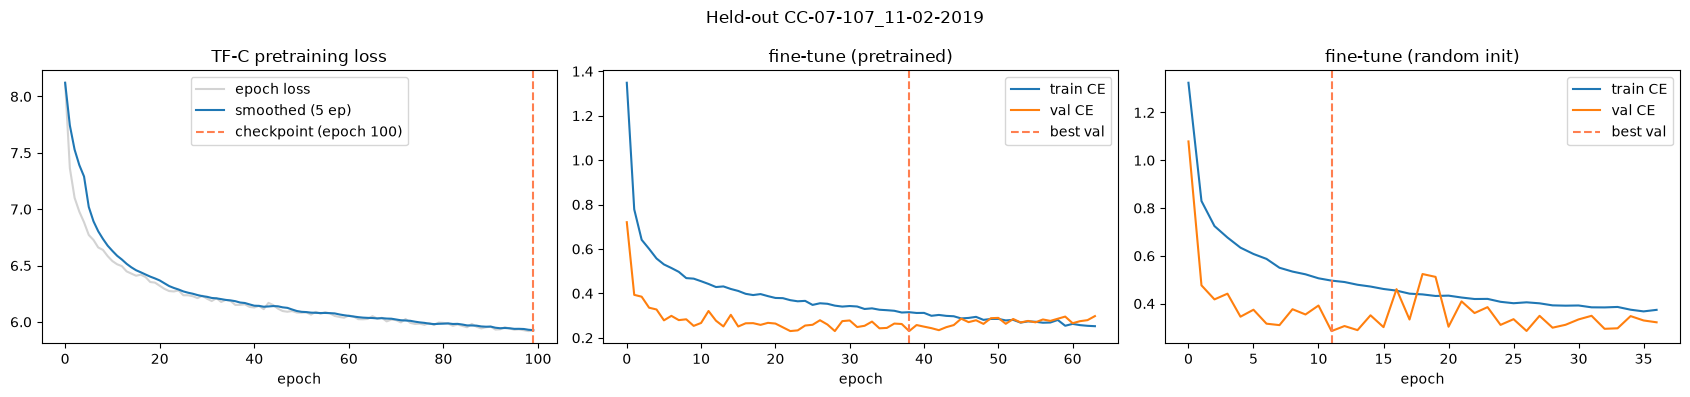

  -> fold 1 macro-F1 (excl. Other): pretrained 0.7761 | random init 0.7583

===== Fold 2/14 | held-out individual: CC-07-108_11-02-2019 (1 recording(s)) =====
  train individuals: ['CC-07-48_06-10-2018', 'CC-07-48_26-05-2018', 'CC-07-115_13-05-2019+14-05-2019', 'CC-07-48_08-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_10-10-2018', 'CC-09-72_04-11-2022', 'CC-07-48_22-05-2018', 'CC-07-48_18-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_08-04-2019'] -> ['CC-07-48_06-10-2018', 'CC-07-48_26-05-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_08-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_10-10-2018', 'CC-09-72_04-11-2022', 'CC-07-48_22-05-2018', 'CC-07-48_18-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3']
  val individuals  : ['CC-07-47_14-02-2018', 'CC-07-48_04-10-2018'] -> ['CC-07-47_14-02-2018', 'CC-07-48_04-10-2018']
  training class balance (timesteps):
Other           69124
Breathing      393949
Feeding        123

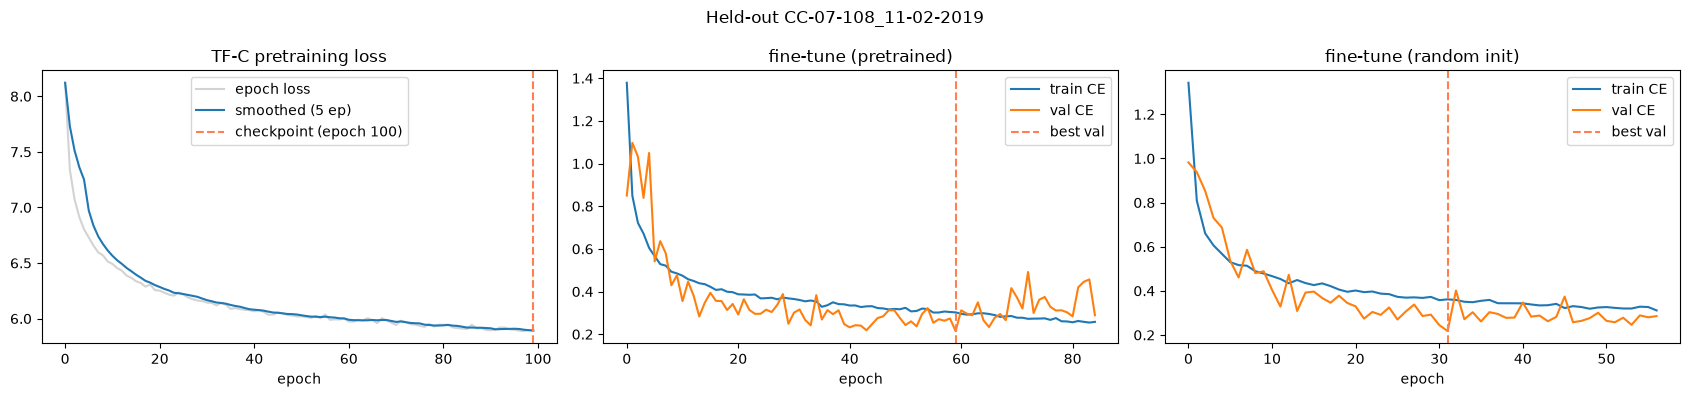

  -> fold 2 macro-F1 (excl. Other): pretrained 0.6210 | random init 0.6528

===== Fold 3/14 | held-out individual: CC-07-115_13-05-2019+14-05-2019 (2 recording(s)) =====
  train individuals: ['CC-07-48_26-05-2018', 'CC-07-48_08-04-2019', 'CC-07-48_04-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_22-05-2018', 'CC-07-48_10-10-2018', 'CC-07-59_20-05-2018', 'CC-07-47_14-02-2018', 'CC-07-48_08-10-2018', 'CC-09-72_04-11-2022', 'CC-07-48_18-02-2019'] -> ['CC-07-48_26-05-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_04-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_22-05-2018', 'CC-07-48_10-10-2018', 'CC-07-59_20-05-2018', 'CC-07-47_14-02-2018', 'CC-07-48_08-10-2018', 'CC-09-72_04-11-2022', 'CC-07-48_18-02-2019']
  val individuals  : ['CC-07-48_06-10-2018', 'CC-07-107_11-02-2019'] -> ['CC-07-48_06-10-2018', 'CC-07-107_11-02-2019']
  training class balance (timesteps):
Other           47859
Breathing      301646
Feeding         76329
Gliding        12868

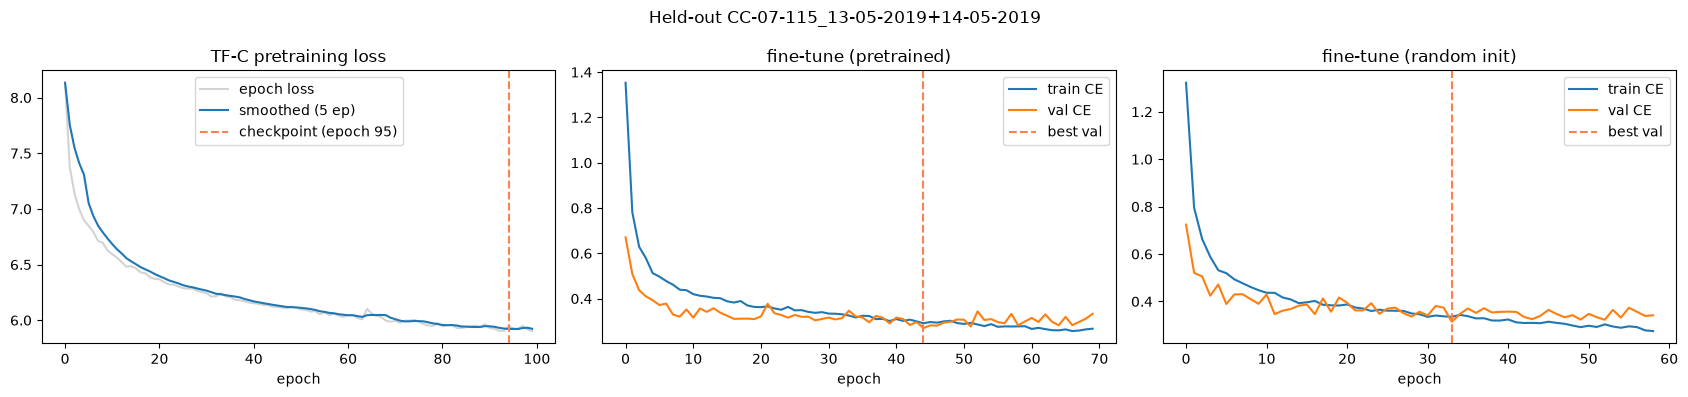

  -> fold 3 macro-F1 (excl. Other): pretrained 0.6346 | random init 0.5559

===== Fold 4/14 | held-out individual: CC-07-47_14-02-2018 (1 recording(s)) =====
  train individuals: ['CC-07-108_11-02-2019', 'CC-07-115_13-05-2019+14-05-2019', 'CC-09-72_04-11-2022', 'CC-07-48_08-04-2019', 'CC-07-48_10-10-2018', 'CC-07-107_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_04-10-2018', 'CC-07-48_22-05-2018', 'CC-07-48_18-02-2019', 'CC-07-48_26-05-2018'] -> ['CC-07-108_11-02-2019', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-09-72_04-11-2022', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_10-10-2018', 'CC-07-107_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_04-10-2018', 'CC-07-48_22-05-2018', 'CC-07-48_18-02-2019', 'CC-07-48_26-05-2018']
  val individuals  : ['CC-07-48_08-10-2018', 'CC-07-48_06-10-2018'] -> ['CC-07-48_08-10-2018', 'CC-07-48_06-10-2018']
  training class balance (timesteps):
Other           57061
Breathing      334755
Feeding         9

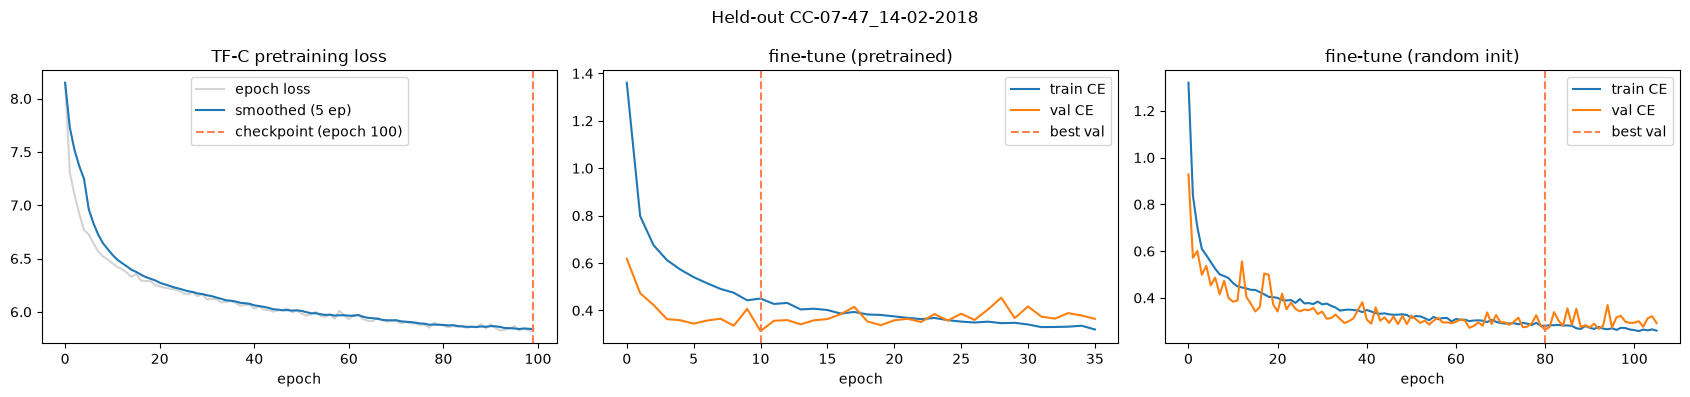

  -> fold 4 macro-F1 (excl. Other): pretrained 0.6331 | random init 0.7865

===== Fold 5/14 | held-out individual: CC-07-48_04-10-2018 (1 recording(s)) =====
  train individuals: ['CC-07-48_08-10-2018', 'CC-09-72_04-11-2022', 'CC-07-48_22-05-2018', 'CC-07-115_13-05-2019+14-05-2019', 'CC-07-107_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_18-02-2019', 'CC-07-108_11-02-2019', 'CC-07-48_08-04-2019', 'CC-07-48_10-10-2018', 'CC-07-48_26-05-2018'] -> ['CC-07-48_08-10-2018', 'CC-09-72_04-11-2022', 'CC-07-48_22-05-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-107_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_18-02-2019', 'CC-07-108_11-02-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_10-10-2018', 'CC-07-48_26-05-2018']
  val individuals  : ['CC-07-47_14-02-2018', 'CC-07-48_06-10-2018'] -> ['CC-07-47_14-02-2018', 'CC-07-48_06-10-2018']
  training class balance (timesteps):
Other           57361
Breathing      358315
Feeding         9

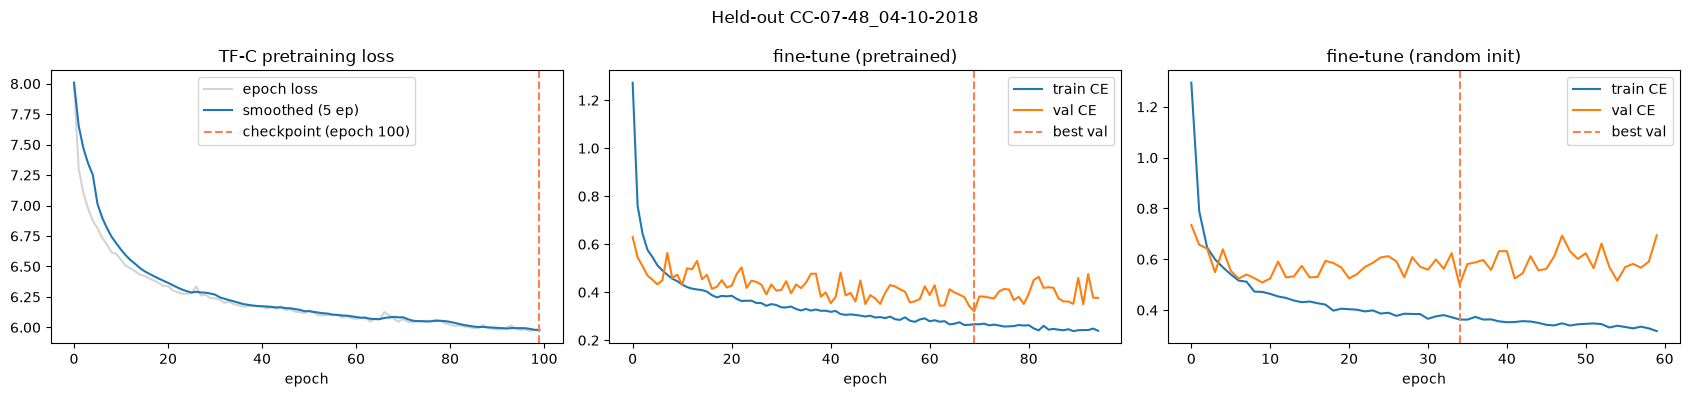

  -> fold 5 macro-F1 (excl. Other): pretrained 0.6374 | random init 0.5848

===== Fold 6/14 | held-out individual: CC-07-48_06-10-2018 (1 recording(s)) =====
  train individuals: ['CC-07-48_10-10-2018', 'CC-07-115_13-05-2019+14-05-2019', 'CC-07-48_22-05-2018', 'CC-09-72_04-11-2022', 'CC-07-48_26-05-2018', 'CC-07-48_04-10-2018', 'CC-07-48_18-02-2019', 'CC-07-107_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_08-10-2018', 'CC-07-47_14-02-2018'] -> ['CC-07-48_10-10-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_22-05-2018', 'CC-09-72_04-11-2022', 'CC-07-48_26-05-2018', 'CC-07-48_04-10-2018', 'CC-07-48_18-02-2019', 'CC-07-107_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_08-10-2018', 'CC-07-47_14-02-2018']
  val individuals  : ['CC-07-48_08-04-2019', 'CC-07-108_11-02-2019'] -> ['CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-108_11-02-2019']
  training class balance (timesteps):
Other           44031
Breathing      349530
Feeding         8

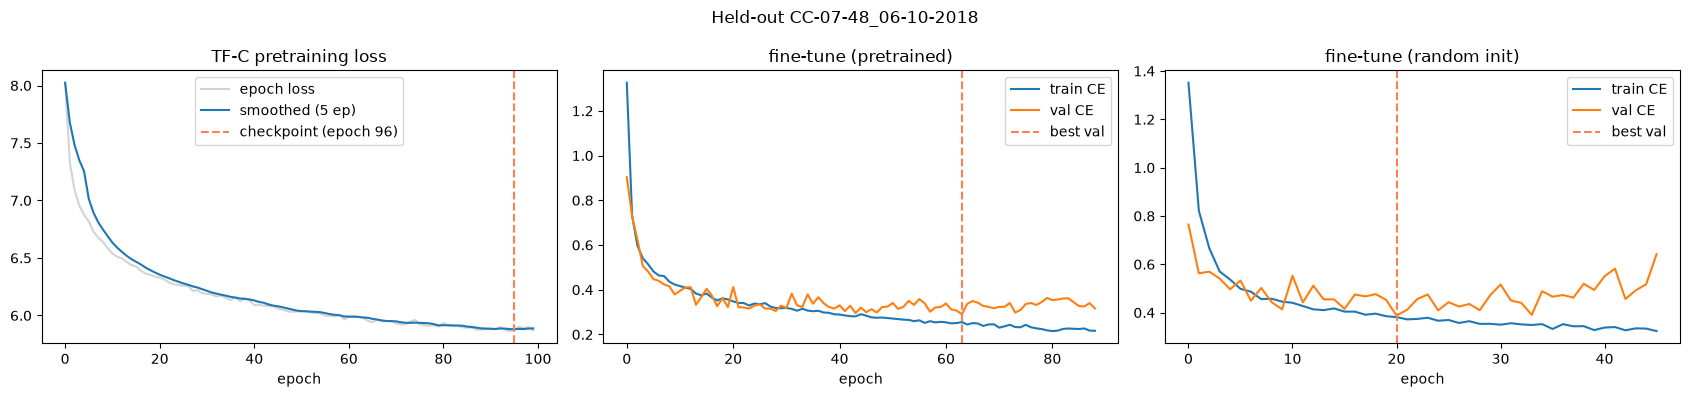

  -> fold 6 macro-F1 (excl. Other): pretrained 0.7335 | random init 0.7253

===== Fold 7/14 | held-out individual: CC-07-48_08-04-2019 (3 recording(s)) =====
  train individuals: ['CC-07-59_20-05-2018', 'CC-07-48_06-10-2018', 'CC-09-72_04-11-2022', 'CC-07-48_10-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_08-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-47_14-02-2018', 'CC-07-48_22-05-2018', 'CC-07-48_26-05-2018'] -> ['CC-07-59_20-05-2018', 'CC-07-48_06-10-2018', 'CC-09-72_04-11-2022', 'CC-07-48_10-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_08-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-47_14-02-2018', 'CC-07-48_22-05-2018', 'CC-07-48_26-05-2018']
  val individuals  : ['CC-07-115_13-05-2019+14-05-2019', 'CC-07-48_18-02-2019'] -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_18-02-2019']
  training class balance (timesteps):
Other           56454
Breathing      315857
Feeding        131636
Gliding        132087
Resting       1583428
Scr

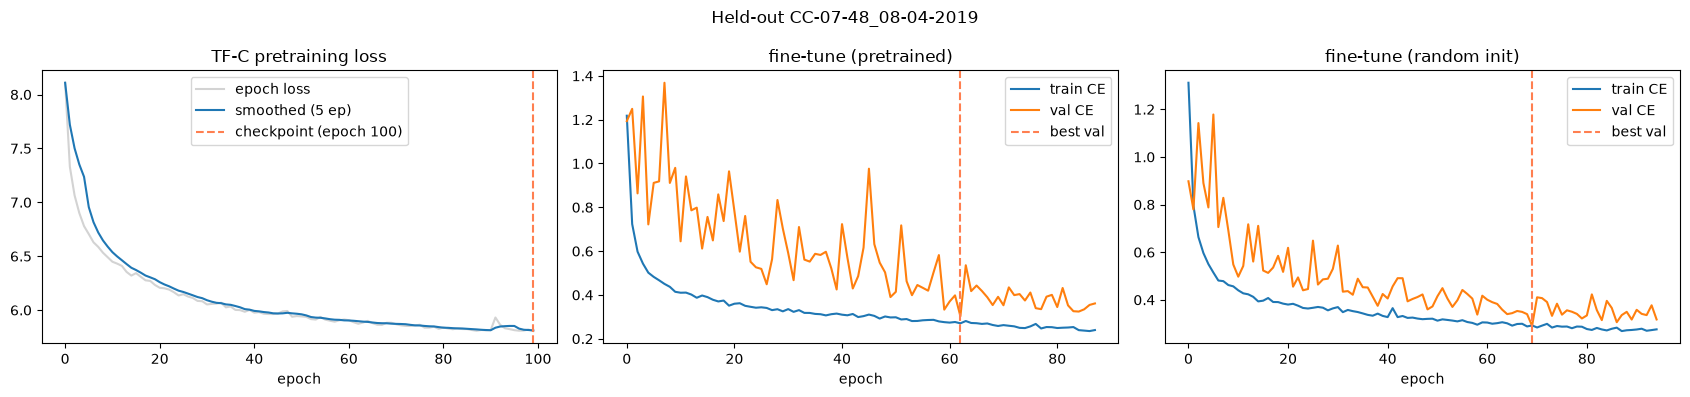

  -> fold 7 macro-F1 (excl. Other): pretrained 0.6376 | random init 0.6704

===== Fold 8/14 | held-out individual: CC-07-48_08-10-2018 (1 recording(s)) =====
  train individuals: ['CC-07-115_13-05-2019+14-05-2019', 'CC-07-48_06-10-2018', 'CC-07-107_11-02-2019', 'CC-07-108_11-02-2019', 'CC-09-72_04-11-2022', 'CC-07-48_10-10-2018', 'CC-07-59_20-05-2018', 'CC-07-47_14-02-2018', 'CC-07-48_08-04-2019', 'CC-07-48_22-05-2018', 'CC-07-48_04-10-2018'] -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_06-10-2018', 'CC-07-107_11-02-2019', 'CC-07-108_11-02-2019', 'CC-09-72_04-11-2022', 'CC-07-48_10-10-2018', 'CC-07-59_20-05-2018', 'CC-07-47_14-02-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_22-05-2018', 'CC-07-48_04-10-2018']
  val individuals  : ['CC-07-48_18-02-2019', 'CC-07-48_26-05-2018'] -> ['CC-07-48_18-02-2019', 'CC-07-48_26-05-2018']
  training class balance (timesteps):
Other           62422
Breathing      324359
Feeding        12

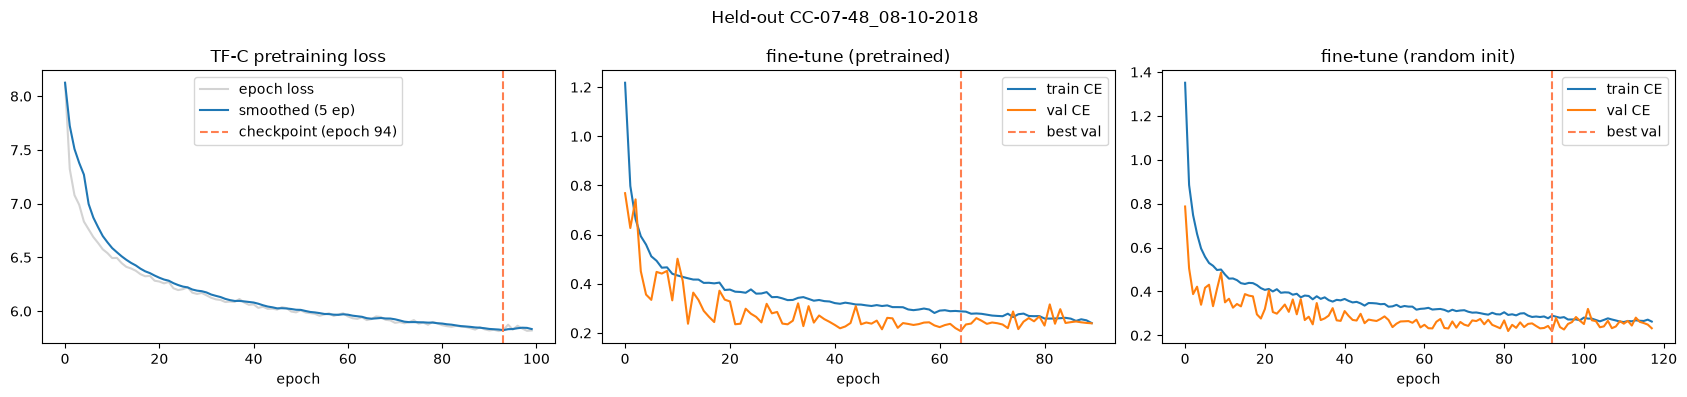

  -> fold 8 macro-F1 (excl. Other): pretrained 0.7091 | random init 0.6645

===== Fold 9/14 | held-out individual: CC-07-48_10-10-2018 (1 recording(s)) =====
  train individuals: ['CC-07-59_20-05-2018', 'CC-07-48_18-02-2019', 'CC-07-48_08-04-2019', 'CC-09-72_04-11-2022', 'CC-07-107_11-02-2019', 'CC-07-115_13-05-2019+14-05-2019', 'CC-07-48_06-10-2018', 'CC-07-48_22-05-2018', 'CC-07-108_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-47_14-02-2018'] -> ['CC-07-59_20-05-2018', 'CC-07-48_18-02-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-09-72_04-11-2022', 'CC-07-107_11-02-2019', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_06-10-2018', 'CC-07-48_22-05-2018', 'CC-07-108_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-47_14-02-2018']
  val individuals  : ['CC-07-48_08-10-2018', 'CC-07-48_26-05-2018'] -> ['CC-07-48_08-10-2018', 'CC-07-48_26-05-2018']
  training class balance (timesteps):
Other           66202
Breathing      345109
Feeding        12

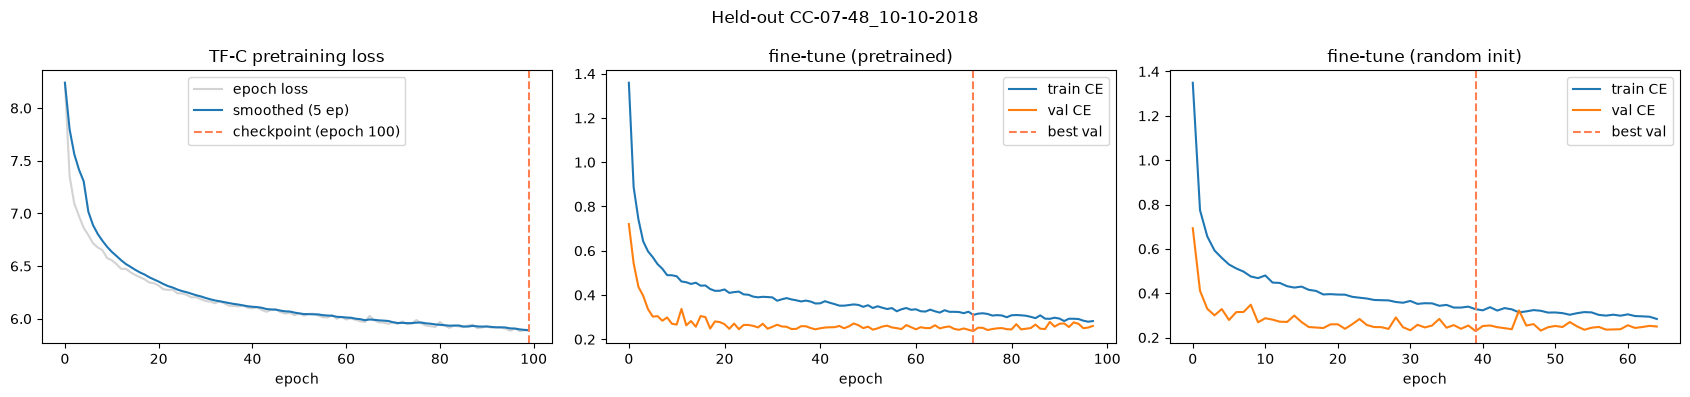

  -> fold 9 macro-F1 (excl. Other): pretrained 0.8312 | random init 0.8368

===== Fold 10/14 | held-out individual: CC-07-48_18-02-2019 (1 recording(s)) =====
  train individuals: ['CC-07-115_13-05-2019+14-05-2019', 'CC-07-107_11-02-2019', 'CC-07-47_14-02-2018', 'CC-07-48_04-10-2018', 'CC-07-108_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_26-05-2018', 'CC-07-48_10-10-2018', 'CC-07-48_08-04-2019', 'CC-07-48_06-10-2018', 'CC-09-72_04-11-2022'] -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-107_11-02-2019', 'CC-07-47_14-02-2018', 'CC-07-48_04-10-2018', 'CC-07-108_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_26-05-2018', 'CC-07-48_10-10-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_06-10-2018', 'CC-09-72_04-11-2022']
  val individuals  : ['CC-07-48_08-10-2018', 'CC-07-48_22-05-2018'] -> ['CC-07-48_08-10-2018', 'CC-07-48_22-05-2018']
  training class balance (timesteps):
Other           64786
Breathing      327023
Feeding        1

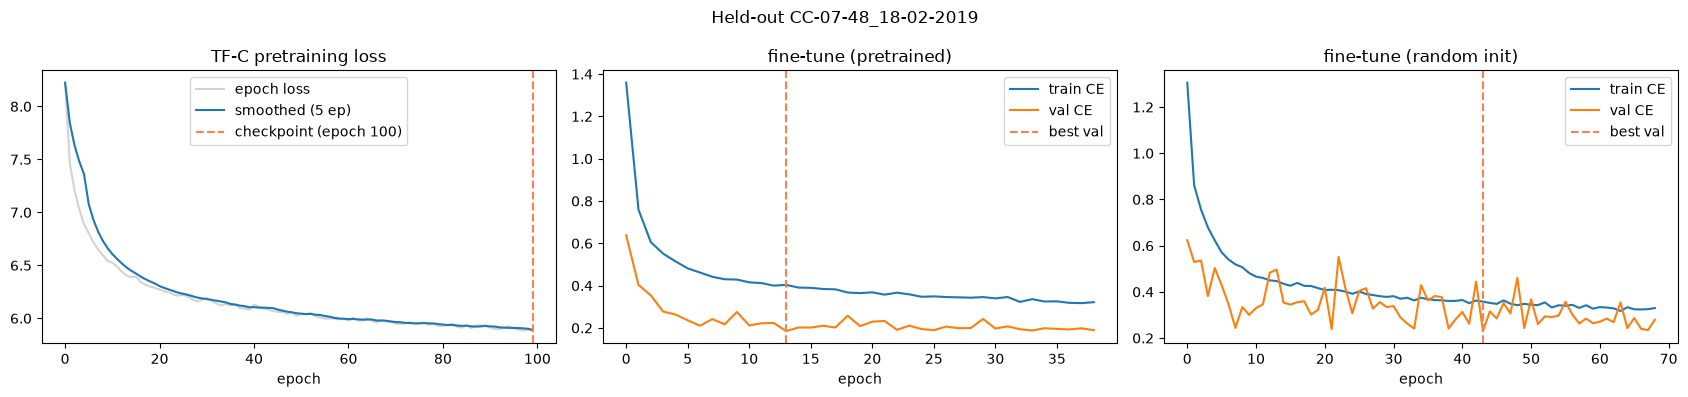

  -> fold 10 macro-F1 (excl. Other): pretrained 0.6579 | random init 0.6305

===== Fold 11/14 | held-out individual: CC-07-48_22-05-2018 (1 recording(s)) =====
  train individuals: ['CC-07-59_20-05-2018', 'CC-07-48_08-04-2019', 'CC-07-48_10-10-2018', 'CC-07-115_13-05-2019+14-05-2019', 'CC-09-72_04-11-2022', 'CC-07-48_06-10-2018', 'CC-07-48_26-05-2018', 'CC-07-108_11-02-2019', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-48_18-02-2019'] -> ['CC-07-59_20-05-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_10-10-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-09-72_04-11-2022', 'CC-07-48_06-10-2018', 'CC-07-48_26-05-2018', 'CC-07-108_11-02-2019', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-48_18-02-2019']
  val individuals  : ['CC-07-47_14-02-2018', 'CC-07-48_08-10-2018'] -> ['CC-07-47_14-02-2018', 'CC-07-48_08-10-2018']
  training class balance (timesteps):
Other           69473
Breathing      358643
Feeding        

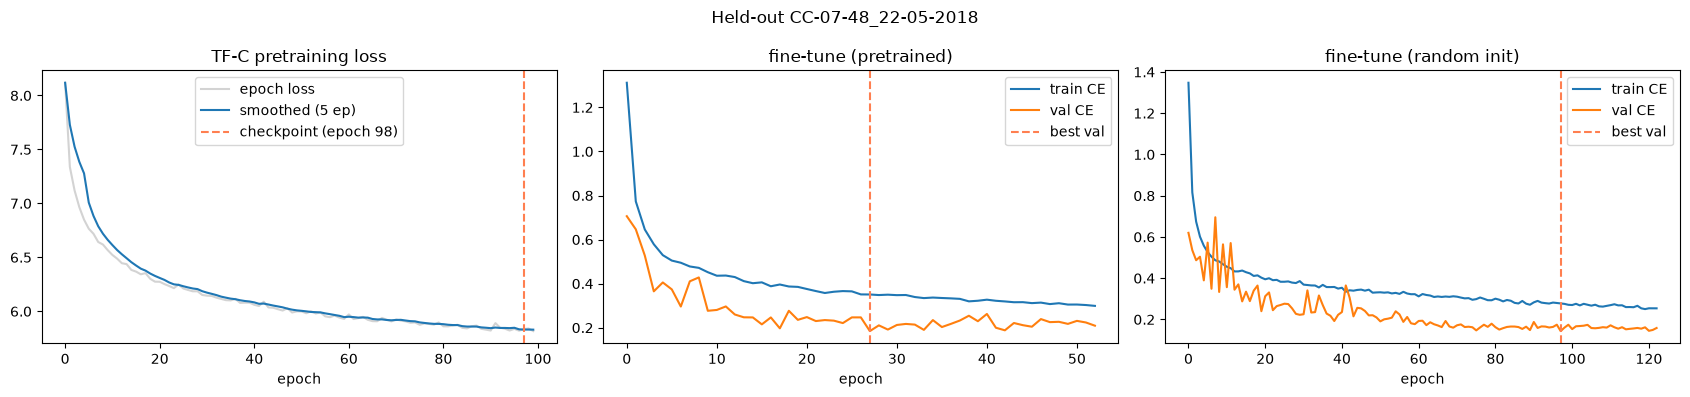

  -> fold 11 macro-F1 (excl. Other): pretrained 0.7962 | random init 0.8036

===== Fold 12/14 | held-out individual: CC-07-48_26-05-2018 (1 recording(s)) =====
  train individuals: ['CC-07-48_10-10-2018', 'CC-07-48_06-10-2018', 'CC-07-48_04-10-2018', 'CC-07-59_20-05-2018', 'CC-07-115_13-05-2019+14-05-2019', 'CC-09-72_04-11-2022', 'CC-07-48_22-05-2018', 'CC-07-48_08-10-2018', 'CC-07-108_11-02-2019', 'CC-07-107_11-02-2019', 'CC-07-48_18-02-2019'] -> ['CC-07-48_10-10-2018', 'CC-07-48_06-10-2018', 'CC-07-48_04-10-2018', 'CC-07-59_20-05-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-09-72_04-11-2022', 'CC-07-48_22-05-2018', 'CC-07-48_08-10-2018', 'CC-07-108_11-02-2019', 'CC-07-107_11-02-2019', 'CC-07-48_18-02-2019']
  val individuals  : ['CC-07-48_08-04-2019', 'CC-07-47_14-02-2018'] -> ['CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-47_14-02-2018']
  training class balance (timesteps):
Other           59466
Breathing      386944
Feeding        

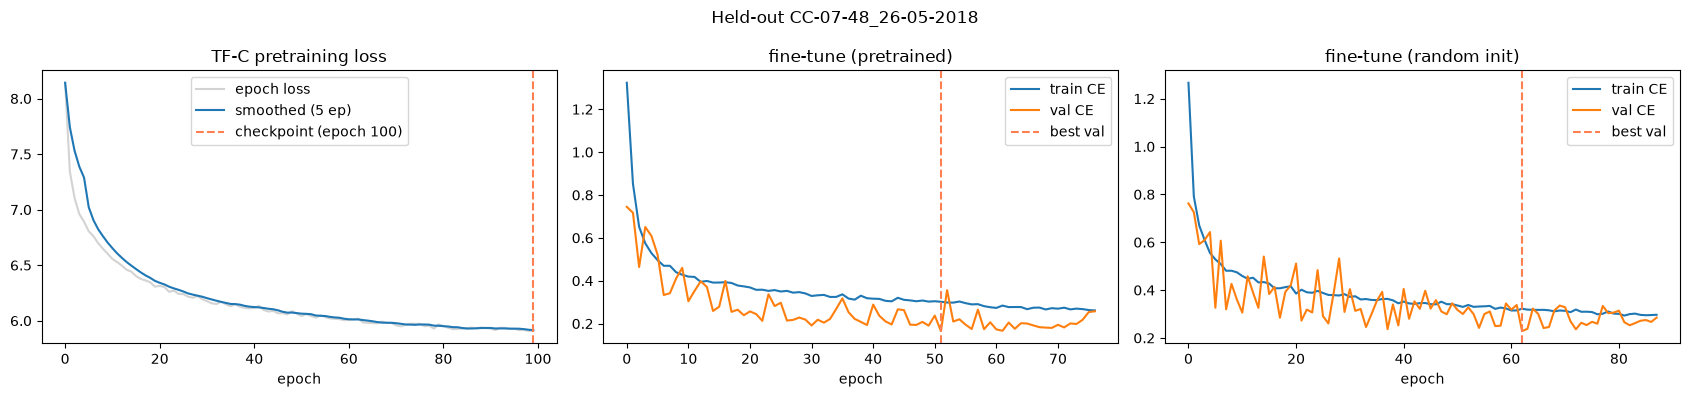

  -> fold 12 macro-F1 (excl. Other): pretrained 0.8325 | random init 0.8030

===== Fold 13/14 | held-out individual: CC-07-59_20-05-2018 (1 recording(s)) =====
  train individuals: ['CC-07-48_18-02-2019', 'CC-07-48_10-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-48_08-10-2018', 'CC-07-47_14-02-2018', 'CC-07-115_13-05-2019+14-05-2019', 'CC-07-108_11-02-2019', 'CC-07-48_08-04-2019', 'CC-09-72_04-11-2022', 'CC-07-48_26-05-2018'] -> ['CC-07-48_18-02-2019', 'CC-07-48_10-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-48_08-10-2018', 'CC-07-47_14-02-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-108_11-02-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-09-72_04-11-2022', 'CC-07-48_26-05-2018']
  val individuals  : ['CC-07-48_22-05-2018', 'CC-07-48_06-10-2018'] -> ['CC-07-48_22-05-2018', 'CC-07-48_06-10-2018']
  training class balance (timesteps):
Other           48851
Breathing      341603
Feeding        

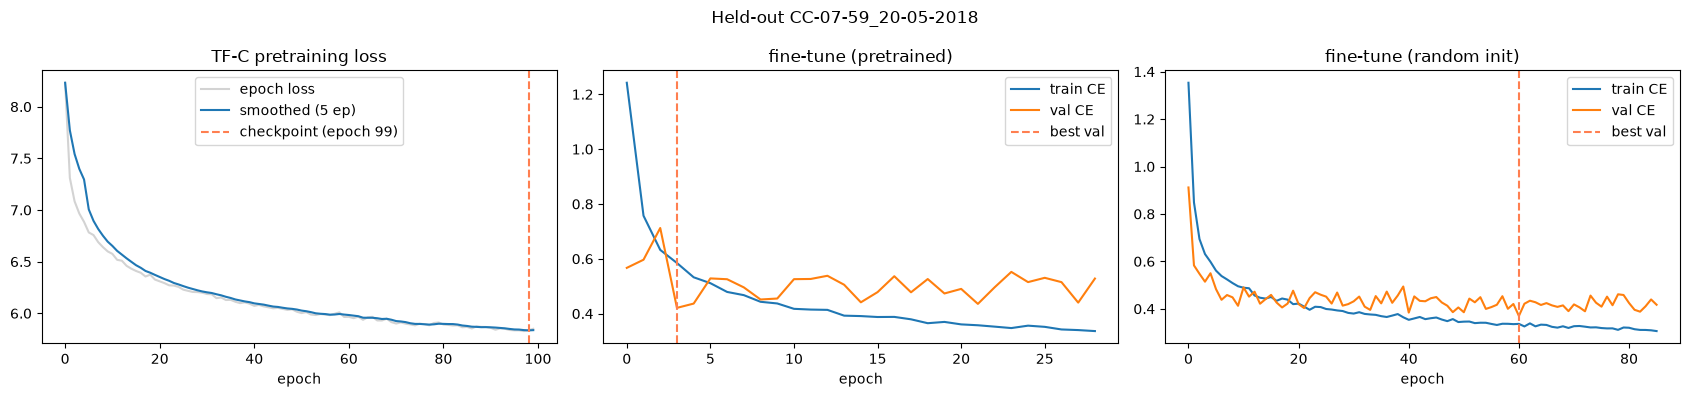

  -> fold 13 macro-F1 (excl. Other): pretrained 0.8061 | random init 0.8069

===== Fold 14/14 | held-out individual: CC-09-72_04-11-2022 (1 recording(s)) =====
  train individuals: ['CC-07-47_14-02-2018', 'CC-07-48_08-10-2018', 'CC-07-48_10-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-59_20-05-2018', 'CC-07-48_08-04-2019', 'CC-07-48_26-05-2018', 'CC-07-48_22-05-2018', 'CC-07-107_11-02-2019', 'CC-07-115_13-05-2019+14-05-2019'] -> ['CC-07-47_14-02-2018', 'CC-07-48_08-10-2018', 'CC-07-48_10-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-59_20-05-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_26-05-2018', 'CC-07-48_22-05-2018', 'CC-07-107_11-02-2019', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019']
  val individuals  : ['CC-07-48_06-10-2018', 'CC-07-48_18-02-2019'] -> ['CC-07-48_06-10-2018', 'CC-07-48_18-02-2019']
  training class balance (timesteps):
Other           53851
Breathing      327462
Feeding        

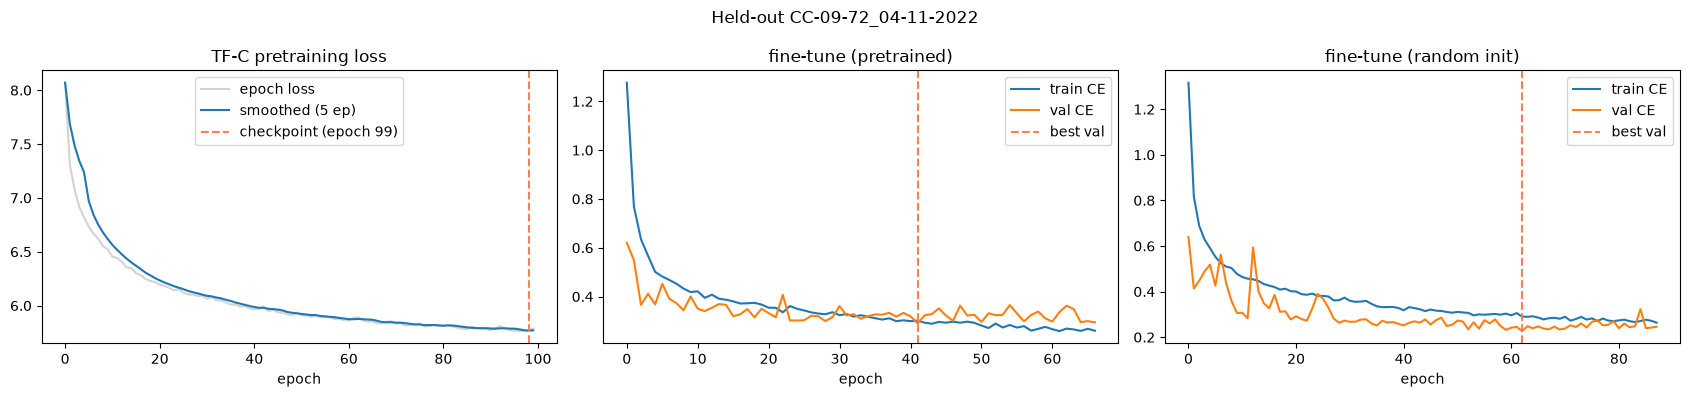

  -> fold 14 macro-F1 (excl. Other): pretrained 0.7502 | random init 0.7897


,fold,test_individual,n_test_recordings,n_train_individuals,n_val_individuals,pretrain_epochs_run,pretrain_best_epoch,pretrain_stopped_early,pretrain_best_smoothed_loss,pretrain_duration_s,...,scratch_best_val_loss,macro_F1_scratch,macro_F1_scratch_all_classes,train_n_Other,train_n_Breathing,train_n_Feeding,train_n_Gliding,train_n_Resting,train_n_Scratching,train_n_Swimming
0,1,CC-07-107_11-02-2019,1,11,2,100,100,False,5.926685,261.443256,...,0.284939,0.758291,0.649963,60684,342245,87542,141751,2032436,76245,1458287
1,2,CC-07-108_11-02-2019,1,11,2,100,100,False,5.893535,268.394910,...,0.217621,0.652790,0.559535,69124,393949,123280,198107,2606553,89914,1473786
2,3,CC-07-115_13-05-2019+14-05-2019,2,11,2,100,95,False,5.922116,257.656551,...,0.314208,0.555860,0.476451,47859,301646,76329,128685,1816064,66794,1189411
3,4,CC-07-47_14-02-2018,1,11,2,100,100,False,5.837342,268.155934,...,0.263776,0.786486,0.786486,57061,334755,99111,179145,2152891,69717,1495962
4,5,CC-07-48_04-10-2018,1,11,2,100,100,False,5.978558,258.533524,...,0.499731,0.584839,0.501291,57361,358315,97465,195018,2392561,72278,1466824
5,6,CC-07-48_06-10-2018,1,11,2,100,96,False,5.879433,264.797512,...,0.387950,0.725258,0.621650,44031,349530,83093,181427,2245756,68118,1508042
6,7,CC-07-48_08-04-2019,3,11,2,100,100,False,5.811452,250.001979,...,0.290628,0.670376,0.574608,56454,315857,131636,132087,1583428,78692,1201824
7,8,CC-07-48_08-10-2018,1,11,2,100,94,False,5.823152,260.190138,...,0.219434,0.664458,0.569536,62422,324359,127220,162220,1932968,51895,1481583
8,9,CC-07-48_10-10-2018,1,11,2,100,100,False,5.890990,268.600009,...,0.229111,0.836807,0.669445,66202,345109,127348,172364,2270338,55427,1595859
9,10,CC-07-48_18-02-2019,1,11,2,100,100,False,5.891801,239.775304,...,0.230212,0.630466,0.540399,64786,327023,134777,165308,1872400,72752,1486761


In [39]:
fold_results = []
per_class_f1_by_fold = {}
summary_path = os.path.join(DIR_OUT, "loocv_f1_summary.csv")

for fold_idx, test_individual in list(enumerate(INDIVIDUAL_IDS))[:MAX_FOLDS]:
    fold_dir = os.path.join(DIR_OUT, "fold_" + test_individual)
    done_json = os.path.join(fold_dir, "fold_result.json")
    done_csv = os.path.join(fold_dir, "per_class_f1.csv")

    if os.path.exists(done_json) and os.path.exists(done_csv):
        print(f"\n===== Fold {fold_idx+1}/{len(INDIVIDUAL_IDS)} | {test_individual}: already finished, loading saved result =====")
        with open(done_json) as f:
            res = json.load(f)
        pcf = pd.read_csv(done_csv, index_col=0)
    else:
        res, pcf = run_fold(fold_idx, test_individual, fold_dir)
        pcf.to_csv(done_csv)
        with open(done_json, "w") as f:
            json.dump(res, f, indent=1)

    fold_results.append(res)
    per_class_f1_by_fold[test_individual] = pcf
    pd.DataFrame(fold_results).to_csv(summary_path, index=False)   # persist progress after every fold

results_df = pd.DataFrame(fold_results)
results_df

In [46]:
pd.set_option("display.width", 250)
cols = ["fold", "test_individual", "macro_F1", "macro_F1_scratch",
        "ft_epochs_run", "ft_best_epoch", "ft_stopped_early",
        "scratch_epochs_run", "scratch_best_epoch", "scratch_stopped_early"]
display(results_df[cols].round(3))

,fold,test_individual,macro_F1,macro_F1_scratch,ft_epochs_run,ft_best_epoch,ft_stopped_early,scratch_epochs_run,scratch_best_epoch,scratch_stopped_early
0,1,CC-07-107_11-02-2019,0.776,0.758,64,39,True,37,12,True
1,2,CC-07-108_11-02-2019,0.621,0.653,85,60,True,57,32,True
2,3,CC-07-115_13-05-2019+14-05-2019,0.635,0.556,70,45,True,59,34,True
3,4,CC-07-47_14-02-2018,0.633,0.786,36,11,True,106,81,True
4,5,CC-07-48_04-10-2018,0.637,0.585,95,70,True,60,35,True
5,6,CC-07-48_06-10-2018,0.734,0.725,89,64,True,46,21,True
6,7,CC-07-48_08-04-2019,0.638,0.670,88,63,True,95,70,True
7,8,CC-07-48_08-10-2018,0.709,0.664,90,65,True,118,93,True
8,9,CC-07-48_10-10-2018,0.831,0.837,98,73,True,65,40,True
9,10,CC-07-48_18-02-2019,0.658,0.630,39,14,True,69,44,True


# Diagnostic

In [44]:
# %% Frozen-feature diagnostic: pretrained vs random-init (linear probe + kNN), plus fine-tuned reference
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

FEATURE_SETS   = ("z", "h")        # z = projector output (what the head sees, 256-d), h = encoder output (32-d)
RANDOM_SEEDS   = (0, 1, 2)         # random-init encoders are averaged over these seeds
PROBE_C_GRID   = (0.01, 0.1, 1.0)  # chosen on the fold's VAL individuals
PROBE_CAP      = 6000              # max training segments per class for the linear probe
KNN_CAP        = 4000              # max training segments per class for kNN
KNN_K          = 15
RECALIBRATE_BN = True              # re-estimate BatchNorm statistics on TRAIN windows for BOTH models (fair; random init has none)
BN_BATCHES     = 40

DIAG_CSV = os.path.join(DIR_OUT, "probe_diagnostic.csv")


def f1_excl_other(y_true, y_pred):
    df = build_metrics_table(y_true, y_pred, class_names)
    return macro_f1(df, exclude=("Other",))


def recalibrate_bn(model, X, n_batches=BN_BATCHES, batch_size=64, seed=0):
    """Re-estimate BatchNorm running stats on TRAIN windows (dropout stays off)."""
    model.train(False)
    bns = [m for m in model.modules() if isinstance(m, nn.BatchNorm1d)]
    for m in bns:
        m.reset_running_stats()
        m.momentum = None            # cumulative average
        m.train(True)
    rng = np.random.RandomState(seed)
    dev = next(model.parameters()).device
    with torch.no_grad():
        for _ in range(n_batches):
            idx = rng.randint(0, len(X), size=min(batch_size, len(X)))
            xb_np = X[idx]
            xb = torch.from_numpy(np.ascontiguousarray(xb_np)).float().permute(0, 2, 1).to(dev)
            xf = freq_to_tensor(np.stack([to_freq(w) for w in xb_np]), dev)
            model.encoder_t(xb)
            model.encoder_f(xf)
    model.train(False)


def extract_features(model, X, batch_size=64):
    """Frozen features per 1.25 s segment. Returns {'z': (N*N_SEG, 256), 'h': (N*N_SEG, 2*TFC_DEPTH)}."""
    model.train(False)
    dev = next(model.parameters()).device
    H, Z = [], []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb_np = X[i:i + batch_size]
            xb = torch.from_numpy(np.ascontiguousarray(xb_np)).float().permute(0, 2, 1).to(dev)
            xf = freq_to_tensor(np.stack([to_freq(w) for w in xb_np]), dev)
            h_t, z_t = model._hz(model.encoder_t, model.capture_t, model.proj_t, xb)
            h_f, z_f = model._hz(model.encoder_f, model.capture_f, model.proj_f, xf)
            H.append(torch.cat([h_t, h_f], dim=2).reshape(-1, h_t.shape[-1] * 2).cpu().numpy())
            Z.append(torch.cat([z_t, z_f], dim=2).reshape(-1, z_t.shape[-1] * 2).cpu().numpy())
    return {"h": np.concatenate(H), "z": np.concatenate(Z)}


def cap_per_class(y, cap, seed=0):
    rng = np.random.RandomState(seed)
    keep = []
    for c in np.unique(y):
        idx = np.flatnonzero(y == c)
        if len(idx) > cap:
            idx = rng.choice(idx, cap, replace=False)
        keep.append(idx)
    return np.sort(np.concatenate(keep))


def probe_and_knn(Ftr, ytr, Fva, yva, Fte, yte):
    """Returns {'linear': F1, 'knn': F1} on the held-out set (macro-F1 excl. Other, per segment)."""
    scaler = StandardScaler().fit(Ftr)
    Ftr_s, Fva_s, Fte_s = scaler.transform(Ftr), scaler.transform(Fva), scaler.transform(Fte)

    # linear probe, C picked on VAL
    sel = cap_per_class(ytr, PROBE_CAP)
    best_c, best_val = None, -1
    for C in PROBE_C_GRID:
        clf = LogisticRegression(C=C, max_iter=300, class_weight="balanced").fit(Ftr_s[sel], ytr[sel])
        v = f1_excl_other(yva, clf.predict(Fva_s))
        if v > best_val:
            best_c, best_val, best_clf = C, v, clf
    lin = f1_excl_other(yte, best_clf.predict(Fte_s))

    # kNN (cosine)
    sel = cap_per_class(ytr, KNN_CAP)
    knn = KNeighborsClassifier(n_neighbors=KNN_K, metric="cosine", algorithm="brute", weights="distance")
    knn.fit(Ftr_s[sel], ytr[sel])
    return {"linear": lin, "knn": f1_excl_other(yte, knn.predict(Fte_s))}


def score_frozen(model, Xtr, ytr, Xva, yva, Xte, yte):
    if RECALIBRATE_BN:
        recalibrate_bn(model, Xtr)
    ftr, fva, fte = (extract_features(model, X) for X in (Xtr, Xva, Xte))
    out = {}
    for fs in FEATURE_SETS:
        res = probe_and_knn(ftr[fs], ytr, fva[fs], yva, fte[fs], yte)
        for probe_name, f1 in res.items():
            out[(fs, probe_name)] = f1
    return out


diag_rows = []
for fold_idx, test_individual in list(enumerate(INDIVIDUAL_IDS))[:MAX_FOLDS]:
    fold_dir = os.path.join(DIR_OUT, "fold_" + test_individual)
    pre_dir = os.path.join(fold_dir, "pretrain")
    if not os.path.exists(os.path.join(pre_dir, "encoder_t_pretrained.pth")):
        print(f"[skip] fold {fold_idx+1} {test_individual}: no pretrained weights in {pre_dir}")
        continue
    print(f"\n=== Fold {fold_idx+1}/{len(INDIVIDUAL_IDS)} | {test_individual} ===")
    set_seed(SEED + fold_idx)
    sp = split_fold(fold_idx, test_individual)

    # frequency standardisation exactly as in the fold (fitted on that fold's pool)
    pool_names, pool_matrices, _, _ = build_pool(sp["train"])
    refit_freq_norm(pool_names, pool_matrices)

    Xtr, ytr = build_eval_set(sp["train"]); ytr = ytr.reshape(-1)
    Xva, yva = build_eval_set(sp["val"]);   yva = yva.reshape(-1)
    Xte, yte = build_eval_set(sp["test"]);  yte = yte.reshape(-1)

    def add(model_name, seed, scores):
        for (fs, probe_name), f1 in scores.items():
            diag_rows.append(dict(fold=fold_idx + 1, test_individual=test_individual, model=model_name,
                                  seed=seed, feats=fs, probe=probe_name, F1=f1))

    # 1) pretrained, frozen
    m = build_tfc_classifier(pretrained=True, pretrain_dir=pre_dir)
    add("pretrained", 0, score_frozen(m, Xtr, ytr, Xva, yva, Xte, yte))
    m.remove_hooks(); del m; free_device_memory()

    # 2) random init, frozen (several seeds)
    for s in RANDOM_SEEDS:
        set_seed(1000 * (s + 1) + fold_idx)
        m = build_tfc_classifier(pretrained=False)
        add("random_init", s, score_frozen(m, Xtr, ytr, Xva, yva, Xte, yte))
        m.remove_hooks(); del m; free_device_memory()

    # 3) reference: the already fine-tuned checkpoints, scored per segment on the same test set
    for name, sub in (("finetuned_pretrained", "finetune"), ("finetuned_scratch", "scratch")):
        ckpt = os.path.join(fold_dir, sub, "tfc_classifier.pth")
        if not os.path.exists(ckpt):
            continue
        m = build_tfc_classifier(pretrained=False)
        m.load_state_dict(torch.load(ckpt, weights_only=True, map_location=device))
        pred = predict_logits(m, Xte).argmax(dim=2).cpu().numpy().reshape(-1)
        diag_rows.append(dict(fold=fold_idx + 1, test_individual=test_individual, model=name, seed=0,
                              feats="-", probe="end-to-end", F1=f1_excl_other(yte, pred)))
        m.remove_hooks(); del m; free_device_memory()

    pd.DataFrame(diag_rows).to_csv(DIAG_CSV, index=False)   # saved after every fold

diag_df = pd.DataFrame(diag_rows)
print("saved:", DIAG_CSV)


=== Fold 1/14 | CC-07-107_11-02-2019 ===


/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules


=== Fold 2/14 | CC-07-108_11-02-2019 ===


/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules


=== Fold 3/14 | CC-07-115_13-05-2019+14-05-2019 ===


...


=== Fold 13/14 | CC-07-59_20-05-2018 ===


/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules


=== Fold 14/14 | CC-09-72_04-11-2022 ===


/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules

saved: Model_results/modelVNET_TFC_LOOCV=2026_10_06_SSL_contrastive_pretrain_B_roll_hinge_seg1.25_LOOCV/probe_diagnostic.csv


In [45]:
# %% Summary: pretrained vs random-init, frozen and fine-tuned
from scipy.stats import wilcoxon

d = (diag_df.groupby(["fold", "test_individual", "model", "feats", "probe"], as_index=False)["F1"].mean())  # averages random-init seeds

rows = []
for (fs, probe), g in d[d.model.isin(["pretrained", "random_init"])].groupby(["feats", "probe"]):
    w = g.pivot(index="test_individual", columns="model", values="F1").dropna()
    diff = w["pretrained"] - w["random_init"]
    try:
        p = wilcoxon(w["pretrained"], w["random_init"]).pvalue
    except Exception:
        p = np.nan
    rows.append(dict(stage=f"frozen {probe} ({fs})", pretrained=w["pretrained"].mean(), random_init=w["random_init"].mean(),
                     diff=diff.mean(), folds_pretrained_better=f"{(diff > 0).sum()}/{len(diff)}", wilcoxon_p=p))

ft = d[d.model.isin(["finetuned_pretrained", "finetuned_scratch"])]
if len(ft):
    w = ft.pivot(index="test_individual", columns="model", values="F1").dropna()
    diff = w["finetuned_pretrained"] - w["finetuned_scratch"]
    try:
        p = wilcoxon(w["finetuned_pretrained"], w["finetuned_scratch"]).pvalue
    except Exception:
        p = np.nan
    rows.append(dict(stage="fine-tuned end-to-end", pretrained=w["finetuned_pretrained"].mean(),
                     random_init=w["finetuned_scratch"].mean(), diff=diff.mean(),
                     folds_pretrained_better=f"{(diff > 0).sum()}/{len(diff)}", wilcoxon_p=p))

summary_diag = pd.DataFrame(rows).round(4)
summary_diag.to_csv(os.path.join(DIR_OUT, "probe_diagnostic_summary.csv"), index=False)
display(summary_diag)

# per-fold view for the headline probe (linear on z)
pf = d[(d.feats.isin(["z", "-"])) & (d.probe.isin(["linear", "end-to-end"]))]
display(pf.pivot(index="test_individual", columns="model", values="F1").round(3))

,stage,pretrained,random_init,diff,folds_pretrained_better,wilcoxon_p
0,frozen knn (h),0.4418,0.3409,0.1009,14/14,0.0001
1,frozen linear (h),0.4596,0.3354,0.1242,14/14,0.0001
2,frozen knn (z),0.4248,0.3445,0.0804,14/14,0.0001
3,frozen linear (z),0.4272,0.3910,0.0362,8/14,0.1189
4,fine-tuned end-to-end,0.7146,0.7213,-0.0067,7/14,1.0000


model,finetuned_pretrained,finetuned_scratch,pretrained,random_init
test_individual,,,,
CC-07-107_11-02-2019,0.760,0.736,0.442,0.446
CC-07-108_11-02-2019,0.613,0.651,0.317,0.323
CC-07-115_13-05-2019+14-05-2019,0.626,0.561,0.309,0.336
CC-07-47_14-02-2018,0.634,0.826,0.389,0.200
CC-07-48_04-10-2018,0.629,0.564,0.300,0.368
CC-07-48_06-10-2018,0.741,0.718,0.474,0.398
CC-07-48_08-04-2019,0.657,0.679,0.436,0.360
CC-07-48_08-10-2018,0.694,0.664,0.475,0.431
CC-07-48_10-10-2018,0.813,0.825,0.446,0.509


## 13. Results

In [40]:
has_scratch = "macro_F1_scratch" in results_df.columns
mean_f1, std_f1 = results_df["macro_F1"].mean(), results_df["macro_F1"].std()
print(f"LOOCV macro F1-score, TF-C pretrained + full fine-tune : {mean_f1:.4f} +/- {std_f1:.4f}  (n={len(results_df)} folds)")
if has_scratch:
    m_sc, s_sc = results_df["macro_F1_scratch"].mean(), results_df["macro_F1_scratch"].std()
    print(f"LOOCV macro F1-score, random init (control)            : {m_sc:.4f} +/- {s_sc:.4f}")
    diff = results_df["macro_F1"] - results_df["macro_F1_scratch"]
    print(f"paired difference (pretrained - random init)           : {diff.mean():+.4f} +/- {diff.std():.4f}; "
          f"pretraining better in {(diff > 0).sum()}/{len(diff)} folds")
    try:
        from scipy.stats import wilcoxon
        print(f"Wilcoxon signed-rank test on the paired fold scores    : p = {wilcoxon(results_df['macro_F1'], results_df['macro_F1_scratch']).pvalue:.4f}")
    except Exception as e:   # e.g. all differences zero, or too few folds
        print("Wilcoxon test not available:", e)
results_df

LOOCV macro F1-score, TF-C pretrained + full fine-tune : 0.7183 +/- 0.0807  (n=14 folds)
LOOCV macro F1-score, random init (control)            : 0.7192 +/- 0.0916
paired difference (pretrained - random init)           : -0.0009 +/- 0.0556; pretraining better in 7/14 folds
Wilcoxon signed-rank test on the paired fold scores    : p = 0.7609


,fold,test_individual,n_test_recordings,n_train_individuals,n_val_individuals,pretrain_epochs_run,pretrain_best_epoch,pretrain_stopped_early,pretrain_best_smoothed_loss,pretrain_duration_s,...,scratch_best_val_loss,macro_F1_scratch,macro_F1_scratch_all_classes,train_n_Other,train_n_Breathing,train_n_Feeding,train_n_Gliding,train_n_Resting,train_n_Scratching,train_n_Swimming
0,1,CC-07-107_11-02-2019,1,11,2,100,100,False,5.926685,261.443256,...,0.284939,0.758291,0.649963,60684,342245,87542,141751,2032436,76245,1458287
1,2,CC-07-108_11-02-2019,1,11,2,100,100,False,5.893535,268.394910,...,0.217621,0.652790,0.559535,69124,393949,123280,198107,2606553,89914,1473786
2,3,CC-07-115_13-05-2019+14-05-2019,2,11,2,100,95,False,5.922116,257.656551,...,0.314208,0.555860,0.476451,47859,301646,76329,128685,1816064,66794,1189411
3,4,CC-07-47_14-02-2018,1,11,2,100,100,False,5.837342,268.155934,...,0.263776,0.786486,0.786486,57061,334755,99111,179145,2152891,69717,1495962
4,5,CC-07-48_04-10-2018,1,11,2,100,100,False,5.978558,258.533524,...,0.499731,0.584839,0.501291,57361,358315,97465,195018,2392561,72278,1466824
5,6,CC-07-48_06-10-2018,1,11,2,100,96,False,5.879433,264.797512,...,0.387950,0.725258,0.621650,44031,349530,83093,181427,2245756,68118,1508042
6,7,CC-07-48_08-04-2019,3,11,2,100,100,False,5.811452,250.001979,...,0.290628,0.670376,0.574608,56454,315857,131636,132087,1583428,78692,1201824
7,8,CC-07-48_08-10-2018,1,11,2,100,94,False,5.823152,260.190138,...,0.219434,0.664458,0.569536,62422,324359,127220,162220,1932968,51895,1481583
8,9,CC-07-48_10-10-2018,1,11,2,100,100,False,5.890990,268.600009,...,0.229111,0.836807,0.669445,66202,345109,127348,172364,2270338,55427,1595859
9,10,CC-07-48_18-02-2019,1,11,2,100,100,False,5.891801,239.775304,...,0.230212,0.630466,0.540399,64786,327023,134777,165308,1872400,72752,1486761


In [41]:
pc_pre = pd.DataFrame({k: v["pretrained"] for k, v in per_class_f1_by_fold.items()})   # rows = class, columns = held-out individual
pc_pre["mean_F1"] = pc_pre.mean(axis=1)                                                  # NaN (class absent from the held-out individual) is skipped
pc_pre["std_F1"] = pc_pre.drop(columns="mean_F1").std(axis=1)
pc_pre.to_csv(os.path.join(DIR_OUT, "loocv_per_class_f1_pretrained.csv"))
print("per-class F1, TF-C pretrained:")
display(pc_pre)

if has_scratch:
    pc_sc = pd.DataFrame({k: v["scratch"] for k, v in per_class_f1_by_fold.items()})
    pc_sc["mean_F1"] = pc_sc.mean(axis=1)
    pc_sc["std_F1"] = pc_sc.drop(columns="mean_F1").std(axis=1)
    pc_sc.to_csv(os.path.join(DIR_OUT, "loocv_per_class_f1_scratch.csv"))
    print("per-class F1, random init (control):")
    display(pc_sc)

per-class F1, TF-C pretrained:


,CC-07-107_11-02-2019,CC-07-108_11-02-2019,CC-07-115_13-05-2019+14-05-2019,CC-07-47_14-02-2018,CC-07-48_04-10-2018,CC-07-48_06-10-2018,CC-07-48_08-04-2019,CC-07-48_08-10-2018,CC-07-48_10-10-2018,CC-07-48_18-02-2019,CC-07-48_22-05-2018,CC-07-48_26-05-2018,CC-07-59_20-05-2018,CC-09-72_04-11-2022,mean_F1,std_F1
Other,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Breathing,0.904157,0.736432,0.943294,0.284845,0.967244,0.847172,0.952898,0.937510,0.927539,0.950065,0.935960,0.963914,0.841916,0.965143,0.868435,0.179934
Feeding,0.790405,0.694889,0.201754,NaN,0.434822,0.681205,0.197501,0.371662,NaN,0.064157,0.605892,0.662176,0.830651,0.753310,0.524035,0.261180
Gliding,0.792304,0.516629,0.670574,NaN,0.547002,0.521477,0.773467,0.787545,0.475531,0.592713,0.722339,0.701037,0.731866,0.791965,0.663419,0.117553
Resting,0.970910,0.859902,0.960560,NaN,0.955778,0.954217,0.895637,0.987002,0.973703,0.990749,0.972076,0.970489,0.974019,0.965649,0.956207,0.037073
Scratching,0.272265,0.057644,0.117685,NaN,0.000000,0.600923,0.187052,0.307286,NaN,0.430896,0.635477,0.828988,0.572672,0.141867,0.346063,0.264491
Swimming,0.926340,0.860515,0.913743,0.981390,0.919445,0.796114,0.819302,0.863557,0.948170,0.918711,0.905377,0.868621,0.885444,0.883262,0.892142,0.049138


per-class F1, random init (control):


,CC-07-107_11-02-2019,CC-07-108_11-02-2019,CC-07-115_13-05-2019+14-05-2019,CC-07-47_14-02-2018,CC-07-48_04-10-2018,CC-07-48_06-10-2018,CC-07-48_08-04-2019,CC-07-48_08-10-2018,CC-07-48_10-10-2018,CC-07-48_18-02-2019,CC-07-48_22-05-2018,CC-07-48_26-05-2018,CC-07-59_20-05-2018,CC-09-72_04-11-2022,mean_F1,std_F1
Other,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Breathing,0.873528,0.832919,0.942827,0.579832,0.949352,0.896358,0.955675,0.922340,0.941601,0.945243,0.954467,0.941985,0.862075,0.966034,0.897445,0.099925
Feeding,0.791415,0.750272,0.069002,NaN,0.249841,0.658016,0.352383,0.154518,NaN,0.040021,0.526000,0.539858,0.871104,0.801768,0.483683,0.301730
Gliding,0.772610,0.519961,0.545405,NaN,0.451767,0.544495,0.758958,0.776050,0.491998,0.624933,0.741969,0.704931,0.768694,0.796881,0.653743,0.127024
Resting,0.965771,0.875690,0.883607,NaN,0.953668,0.964365,0.934759,0.984576,0.970486,0.988486,0.975777,0.962844,0.974215,0.967689,0.953995,0.035647
Scratching,0.232393,0.047231,0.028990,NaN,0.000000,0.496173,0.169277,0.296260,NaN,0.278125,0.703367,0.805758,0.473356,0.308000,0.319911,0.257934
Swimming,0.914027,0.890668,0.865327,0.993141,0.904408,0.792139,0.851205,0.853005,0.943143,0.905987,0.919735,0.862343,0.892171,0.897659,0.891783,0.047418


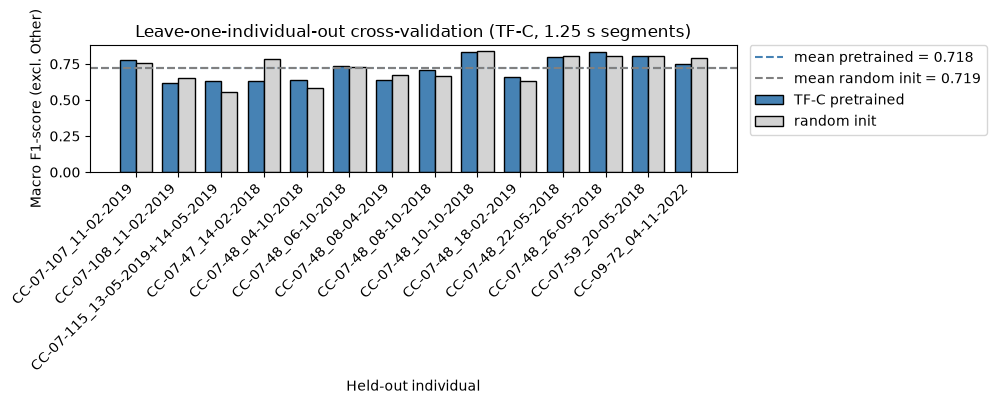

In [43]:
x = np.arange(len(results_df))
w = 0.38 if has_scratch else 0.6

plt.figure(figsize=(10, 4))
plt.bar(
    x - (w / 2 if has_scratch else 0),
    results_df["macro_F1"],
    width=w,
    color="steelblue",
    edgecolor="k",
    label="TF-C pretrained",
)
plt.axhline(
    mean_f1,
    color="steelblue",
    linestyle="--",
    label=f"mean pretrained = {mean_f1:.3f}",
)

if has_scratch:
  plt.bar(
      x + w / 2,
      results_df["macro_F1_scratch"],
      width=w,
      color="lightgray",
      edgecolor="k",
      label="random init",
  )
  plt.axhline(
      m_sc,
      color="gray",
      linestyle="--",
      label=f"mean random init = {m_sc:.3f}",
  )

plt.ylabel("Macro F1-score (excl. Other)")
plt.xlabel("Held-out individual")
plt.title("Leave-one-individual-out cross-validation (TF-C, 1.25 s segments)")
plt.xticks(x, results_df["test_individual"], rotation=45, ha="right")

# Place legend outside the plot to the upper right
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)

plt.tight_layout()
plt.savefig(
    os.path.join(DIR_OUT, "loocv_f1_per_fold.png"), bbox_inches="tight"
)  # Added bbox_inches='tight' so the legend isn't clipped when saved
plt.show()

In [ ]:
# %% Per-class frozen-probe F1: pretrained vs random-init (+ fine-tuned reference)
PERCLASS_CSV = os.path.join(DIR_OUT, "probe_diagnostic_per_class.csv")


def probe_knn_perclass(Ftr, ytr, Fva, yva, Fte, yte):
    """Returns {'linear': (F1 per class, support), 'knn': (...)}; F1 is NaN for classes absent from the test set."""
    scaler = StandardScaler().fit(Ftr)
    Ftr_s, Fva_s, Fte_s = scaler.transform(Ftr), scaler.transform(Fva), scaler.transform(Fte)

    # linear probe, C chosen on VAL (macro-F1 excl. Other), then scored per class on TEST
    sel = cap_per_class(ytr, PROBE_CAP)
    best_val, best_clf = -1, None
    for C in PROBE_C_GRID:
        clf = LogisticRegression(C=C, max_iter=300, class_weight="balanced").fit(Ftr_s[sel], ytr[sel])
        v = f1_excl_other(yva, clf.predict(Fva_s))
        if v > best_val:
            best_val, best_clf = v, clf
    df_lin = build_metrics_table(yte, best_clf.predict(Fte_s), class_names)

    # kNN (cosine)
    sel = cap_per_class(ytr, KNN_CAP)
    knn = KNeighborsClassifier(n_neighbors=KNN_K, metric="cosine", algorithm="brute", weights="distance")
    knn.fit(Ftr_s[sel], ytr[sel])
    df_knn = build_metrics_table(yte, knn.predict(Fte_s), class_names)

    return {"linear": df_lin, "knn": df_knn}


pc_rows = []

def add_pc(fold_idx, test_individual, model_name, seed, feats, probe, df):
    f1 = per_class_f1(df)
    for cname in class_names:
        pc_rows.append(dict(fold=fold_idx + 1, test_individual=test_individual, model=model_name, seed=seed,
                            feats=feats, probe=probe, cls=cname, F1=f1[cname], support=int(df.loc[cname, "Support"])))


def frozen_perclass(model, Xtr, ytr, Xva, yva, Xte, yte):
    if RECALIBRATE_BN:
        recalibrate_bn(model, Xtr)
    ftr, fva, fte = (extract_features(model, X) for X in (Xtr, Xva, Xte))
    out = {}
    for fs in FEATURE_SETS:
        for probe, df in probe_knn_perclass(ftr[fs], ytr, fva[fs], yva, fte[fs], yte).items():
            out[(fs, probe)] = df
    return out


for fold_idx, test_individual in list(enumerate(INDIVIDUAL_IDS))[:MAX_FOLDS]:
    fold_dir = os.path.join(DIR_OUT, "fold_" + test_individual)
    pre_dir = os.path.join(fold_dir, "pretrain")
    if not os.path.exists(os.path.join(pre_dir, "encoder_t_pretrained.pth")):
        print(f"[skip] fold {fold_idx+1} {test_individual}")
        continue
    print(f"=== Fold {fold_idx+1}/{len(INDIVIDUAL_IDS)} | {test_individual} ===")
    set_seed(SEED + fold_idx)
    sp = split_fold(fold_idx, test_individual)
    pool_names, pool_matrices, _, _ = build_pool(sp["train"])
    refit_freq_norm(pool_names, pool_matrices)

    Xtr, ytr = build_eval_set(sp["train"]); ytr = ytr.reshape(-1)
    Xva, yva = build_eval_set(sp["val"]);   yva = yva.reshape(-1)
    Xte, yte = build_eval_set(sp["test"]);  yte = yte.reshape(-1)

    # frozen pretrained
    m = build_tfc_classifier(pretrained=True, pretrain_dir=pre_dir)
    for (fs, probe), df in frozen_perclass(m, Xtr, ytr, Xva, yva, Xte, yte).items():
        add_pc(fold_idx, test_individual, "pretrained", 0, fs, probe, df)
    m.remove_hooks(); del m; free_device_memory()

    # frozen random init (several seeds)
    for s in RANDOM_SEEDS:
        set_seed(1000 * (s + 1) + fold_idx)
        m = build_tfc_classifier(pretrained=False)
        for (fs, probe), df in frozen_perclass(m, Xtr, ytr, Xva, yva, Xte, yte).items():
            add_pc(fold_idx, test_individual, "random_init", s, fs, probe, df)
        m.remove_hooks(); del m; free_device_memory()

    # fine-tuned reference (already trained checkpoints)
    for name, sub in (("finetuned_pretrained", "finetune"), ("finetuned_scratch", "scratch")):
        ckpt = os.path.join(fold_dir, sub, "tfc_classifier.pth")
        if not os.path.exists(ckpt):
            continue
        m = build_tfc_classifier(pretrained=False)
        m.load_state_dict(torch.load(ckpt, weights_only=True, map_location=device))
        pred = predict_logits(m, Xte).argmax(dim=2).cpu().numpy().reshape(-1)
        add_pc(fold_idx, test_individual, name, 0, "-", "end-to-end", build_metrics_table(yte, pred, class_names))
        m.remove_hooks(); del m; free_device_memory()

    pd.DataFrame(pc_rows).to_csv(PERCLASS_CSV, index=False)

pc_df = pd.DataFrame(pc_rows)
print("saved:", PERCLASS_CSV)

=== Fold 1/14 | CC-07-107_11-02-2019 ===


/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules

=== Fold 2/14 | CC-07-108_11-02-2019 ===


/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules

=== Fold 3/14 | CC-07-115_13-05-2019+14-05-2019 ===


/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/24823716/Downloads/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules

KeyboardInterrupt: 

In [ ]:
# %% Per-class summary: pretrained vs random-init
from scipy.stats import wilcoxon

# average random-init seeds first, so each (fold, model, feats, probe, class) is one number
g = pc_df.groupby(["fold", "test_individual", "model", "feats", "probe", "cls"], as_index=False)["F1"].mean()

def compare(g, a, b, feats, probe):
    sub = g[(g.feats == feats) & (g.probe == probe) & (g.model.isin([a, b]))]
    rows = []
    for cname in class_names:
        w = sub[sub.cls == cname].pivot(index="test_individual", columns="model", values="F1").dropna()
        if len(w) < 3:
            continue
        diff = w[a] - w[b]
        try:
            p = wilcoxon(w[a], w[b]).pvalue
        except Exception:
            p = np.nan
        rows.append({"class": cname, "n_folds": len(w), a: w[a].mean(), b: w[b].mean(),
                     "diff": diff.mean(), "better": f"{(diff > 0).sum()}/{len(diff)}", "wilcoxon_p": p})
    return pd.DataFrame(rows).set_index("class").round(3)

for fs, probe in [("z", "linear"), ("h", "linear"), ("z", "knn"), ("h", "knn")]:
    if ((g.feats == fs) & (g.probe == probe)).any():
        print(f"\n--- FROZEN {probe} on {fs}: pretrained vs random_init ---")
        display(compare(g, "pretrained", "random_init", fs, probe))

print("\n--- FINE-TUNED end-to-end: pretrained vs scratch ---")
display(compare(g, "finetuned_pretrained", "finetuned_scratch", "-", "end-to-end"))

In [ ]:
# %% Plot per-class F1 (frozen linear on z, and fine-tuned)
import matplotlib.pyplot as plt

TARGETS = ["Feeding", "Scratching", "Gliding"]       # guardrails: Resting, Swimming
SHOW = TARGETS + ["Resting", "Swimming", "Breathing"]

def mean_f1(model, feats, probe):
    s = g[(g.model == model) & (g.feats == feats) & (g.probe == probe)].groupby("cls")["F1"].mean()
    return [s.get(c, np.nan) for c in SHOW]

panels = [("Frozen linear probe (z)", ("pretrained", "z", "linear"), ("random_init", "z", "linear")),
          ("Fine-tuned end-to-end", ("finetuned_pretrained", "-", "end-to-end"), ("finetuned_scratch", "-", "end-to-end"))]

fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
x = np.arange(len(SHOW)); w = 0.38
for ax, (title, A, B) in zip(axs, panels):
    ax.bar(x - w/2, mean_f1(*A), w, color="steelblue", edgecolor="k", label="pretrained")
    ax.bar(x + w/2, mean_f1(*B), w, color="lightgray", edgecolor="k", label="random init / scratch")
    ax.set_xticks(x); ax.set_xticklabels(SHOW, rotation=30, ha="right")
    ax.set_title(title); ax.set_ylim(0, 1)
axs[0].set_ylabel("Mean per-class F1 over folds (segments)")
axs[0].legend()
fig.tight_layout()
fig.savefig(os.path.join(DIR_OUT, "probe_per_class_f1.png"), bbox_inches="tight")
plt.show()

# per-fold detail for the target classes (frozen linear on z)
detail = g[(g.feats == "z") & (g.probe == "linear") & (g.cls.isin(TARGETS)) & (g.model.isin(["pretrained", "random_init"]))]
display(detail.pivot_table(index="test_individual", columns=["cls", "model"], values="F1").round(3))